# 06 - Evaluation and Results

**Continues:** Model 1 (notebook 04) and Model 2 (notebook 05).

**Question:** which candidates are genuine performance losses, what did they cost the line, where did they happen,
and how sure are we?

| Term | Meaning here | Done where |
|---|---|---|
| **Internal checks** | the steps of a notebook agree with each other and with the team's original cells | check cells in 02-06 |
| **Sensitivity analysis** | the conclusion survives justified parameter changes | 04 (thresholds, clock shift, time grid) |
| **Cross-checking** | another method or rule gives a consistent result | Model 2 (05), line-quiet check (here) |
| **Independent validation** | a signal that did not define the detection confirms it | stop states, light barriers, encoder (04) |
| **Cross-validation** | data partitioning to measure generalisation | **not performed** - no labels, one recording |

Agreement between two methods is reported as agreement, never as proof. Outputs: `reports/evidence_tables.xlsx` and
the figures `cycle_effect`, `method_comparison`, `performance_bounds`.

## Setup

Imports, parameters (the same values as `config.yaml`) and the hand-over of results between the notebooks (`data/processed/`, run the notebooks in order 01-06).

In [1]:
from io import StringIO
from pathlib import Path

from IPython.display import Image, display
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
import re
from scipy import stats as sps
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import dataclasses
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [2]:
# Parameters - the same values as config.yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = {'paths': {'raw_siemens': 'data/raw/Beispieldatensatz Siemens S7 SPS.csv',
           'raw_beckhoff': 'data/raw/Beispieldatensatz Beckhoff SPS.csv',
           'variable_file': 'data/raw/Variablenerklärung.xlsx',
           'reports_dir': 'reports',
           'figures_dir': 'reports/figures'},
 'timebase': {'gap_report_s': 0.5,
              'gap_cooccur_tolerance_s': 0.2,
              'resample_grids_ms': [20, 50, 76, 93, 100, 200, 500]},
 'phases': {'production_start_signal': 'E200.0',
            'curtain_signal': 'A201.0',
            'curtain_signal_beckhoff': 'VG.safeCurtainShort',
            'hmi_run_signal': 'Visual.start',
            'pallet_request_signals': ['WH.desiredPalletX', 'WH.desiredPalletY'],
            'drilling_cycle_register': 'MW22'},
 'rule': {'tukey_k': 3.0,
          'min_activations': 5,
          'min_excess_s': 'auto',
          'sweep_k': [1.5, 3.0],
          'sweep_min_excess_s': [1.0, 1.5, 1.84, 2.0, 2.5, 3.0, 4.0, 5.0],
          'sweep_merge_gap_s': [0.0, 1.0, 2.0, 5.0, 10.0],
          'merge_gap_s': 0.0},
 'ml': {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        'contamination_sweep': [0.01, 0.02, 0.05, 0.1],
        'kmeans_k': [2, 3, 4, 5, 6, 7, 8],
        'top_k': 10},
 'performance': {'bootstrap_resamples': 5000, 'bootstrap_seed': 42}}
cfg["paths"] = {k: ROOT / v for k, v in cfg["paths"].items()}
PROCESSED = ROOT / "data" / "processed"        # prepared data handed from one notebook to the next
FIGURES = cfg["paths"]["figures_dir"]          # reports/figures

In [3]:
def save_stage(name, results):
    """Write this notebook's results to data/processed/<name>.pkl for the next notebooks."""
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(results, PROCESSED / f"{name}.pkl")


def load_stage(name, notebook):
    """Results of an earlier notebook; a clear message names the notebook to run first."""
    f = PROCESSED / f"{name}.pkl"
    if not f.exists():
        raise FileNotFoundError(f"data/processed/{name}.pkl is missing - run notebook {notebook} first.")
    return pd.read_pickle(f)

**Figure style** (the same cell in every notebook that saves figures): 12 x 5.4 in, 200 dpi, fonts >= 12 pt, fixed colours.

In [4]:
COLORS = {"stop": "#D64545", "overrun": "#F0A030", "normal": "#9AA5B1", "accent": "#1F7A8C",
          "navy": "#1F2A5A", "light": "#E6E9ED", "muted": "#5B6675"}


FIGSIZE = (12, 5.4)


DPI = 200


STYLE = {
    "figure.figsize": FIGSIZE, "figure.dpi": 100, "savefig.dpi": DPI, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": 13, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 13, "xtick.labelsize": 12,
    "ytick.labelsize": 12, "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#5B6675", "axes.labelcolor": "#1F2A5A", "text.color": "#1F2A5A",
    "xtick.color": "#1F2A5A", "ytick.color": "#1F2A5A", "legend.frameon": False,
}


def apply_style():
    plt.rcParams.update(STYLE)


apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)

**Data container**

- `PLCData`: Analysis-ready recording of one PLC.

In [5]:
@dataclass
class PLCData:
    """Analysis-ready recording of one PLC."""

    name: str
    frame: pd.DataFrame                 # timestamp, t, one column per signal
    signals: list[str]
    raw_shape: tuple[int, int]          # rows, signal columns (as in the file)
    excluded_rows: pd.DataFrame = field(default_factory=pd.DataFrame)
    dropped_columns: list[str] = field(default_factory=list)

In [6]:
s02 = load_stage("02_data", "02_data_understanding_and_cleaning")
s03 = load_stage("03_prepared", "03_data_preparation")
s04 = load_stage("04_model1", "04_model_1_engineering_detection")
s05 = load_stage("05_model2", "05_model_2_machine_learning")
data = {k: PLCData(**v) if k in ("Siemens", "Beckhoff") else v for k, v in s02.pop("data").items()}
ctx = {"cfg": cfg, "data": data, **s02, **s03, **s04, **s05}      # notebooks 02-05
events, flags, feat, acts, cycles = ctx["events"], ctx["flags"], ctx["feat"], ctx["acts"], ctx["cycles"]

**Evaluation functions (the time-grid test comes from notebook 04)**

- `overlaps`: True if two time windows share at least one moment.
- `STOP_TOL_S`: Tolerance (s) for 'cut by' / 'restarted after' a stop window.

In [7]:
def overlaps(a0, a1, b0, b1) -> bool:
    return a0 <= b1 and b0 <= a1


# One logging step of either PLC: edges of the same stop can be logged this
# far apart on the two PLCs (measured offset <= 0.09 s, median steps 0.08/0.09 s).
STOP_TOL_S = 0.25

- `scored_activations`: Activations usable for duration statistics: in production, complete.
- `actuator_edge_times`: Times of every actuator edge of both PLCs (optionally of one station).
- `quiet_periods`: Periods between consecutive actuator edges.
- `quiet_completeness`: Every period without any actuator edge (both PLCs) that is longer than

In [8]:
def scored_activations(acts: pd.DataFrame) -> pd.DataFrame:
    """Activations usable for duration statistics: in production, complete."""
    return acts[acts["in_production"] & ~acts["open_at_start"] & ~acts["open_at_end"]].copy()


def actuator_edge_times(data: dict, actuators: dict, p0: float, station: str | None = None) -> np.ndarray:
    out = []
    for plc, sigs in actuators.items():
        d = data[plc].frame
        doc = data["doc"][plc].set_index("signal")
        use = [c for c in sigs if station is None or (c in doc.index and doc.loc[c, "station"] == station)]
        if not use:
            continue
        v = d[use].astype(int).to_numpy()
        ch = np.r_[False, (np.abs(np.diff(v, axis=0)).sum(axis=1) > 0)]
        out.append(d["t"].to_numpy()[ch])
    t = np.sort(np.concatenate(out)) if out else np.array([])
    return t[t >= p0]


def quiet_periods(times: np.ndarray) -> pd.DataFrame:
    q = pd.DataFrame({"start_s": times[:-1], "end_s": times[1:]})
    q["duration_s"] = q["end_s"] - q["start_s"]
    return q


def quiet_completeness(data: dict, actuators: dict, p0: float, cycles_done: pd.DataFrame,
                       events: pd.DataFrame, acts: pd.DataFrame, flag_keys: set) -> tuple[pd.DataFrame, float]:
    """Every period without any actuator edge (both PLCs) that is longer than
    the longest such period inside clean cycles must lie inside an event or
    inside a movement of normal length. Returns the table and the limit."""
    t = actuator_edge_times(data, actuators, p0)
    q = quiet_periods(t)
    clean = cycles_done[cycles_done["events"] == ""]
    in_clean = np.zeros(len(q), bool)
    for _, c in clean.iterrows():
        in_clean |= ((q["start_s"] >= c["start_s"]) & (q["end_s"] <= c["end_s"])).to_numpy()
    limit = float(q.loc[in_clean, "duration_s"].max())
    sc = scored_activations(acts)
    normal = sc[[k not in flag_keys for k in zip(sc["signal"], sc["start"])]]
    longest = normal.groupby("signal")["duration"].max()
    long_q = q[q["duration_s"] > limit].copy()

    def why(a, b):
        for _, ev in events.iterrows():
            if overlaps(a, b, ev["start_s"], ev["end_s"]):
                return f"inside event {ev['event']}"
        cov = acts[(acts["start"] <= a) & (acts["end"] >= b)]
        for _, r in cov.iterrows():
            if r["signal"] in longest.index and r["duration"] <= longest[r["signal"]]:
                return f"normal move {r['signal']} ({r['duration']:.2f} s <= {longest[r['signal']]:.2f} s)"
        return "NOT EXPLAINED"

    long_q["explained_by"] = [why(a, b) for a, b in zip(long_q["start_s"], long_q["end_s"])]
    return long_q.reset_index(drop=True), limit

- `UNEXPLAINED`: Label of a candidate that is longer than normal and not explained.

In [9]:
UNEXPLAINED = "UNEXPLAINED: longer than normal, not flagged - review trace"

- `exact_permutation_p`: One-sided exact permutation test: mean(event) - mean(clean).
- `cycle_effect`: Cycle durations with and without events and the exact permutation test.
- `_clipped_on_time`: ON time of some outputs clipped to a time window.
- `_union_length`: Total length of a union of intervals.
- `VERTICAL`: Vertical warehouse motor outputs.
- `chain_coverage`: Share of each pallet cycle in which a warehouse or robot output is ON.
- `chain_handover`: Hand-over delays on the serial chain, per cycle (measured).
- `event_chain_effect`: Did the event lengthen the serial warehouse + robot chain? (measured rule)
- `cycle_reference`: Position-adjusted normal reference time for every complete pallet cycle.
- `performance_estimates`: Performance of the complete cycles under several reference times.
- `STOP_SIGNALS`: Signals that confirm each stop mechanism.
- `evidence_register`: One row per final event: what detected it, what independently confirms it,
- `candidate_register`: Every candidate the methods produced and what became of it.
- `NOT_AVAILABLE`: Text for a value that cannot be computed.
- `_pct`: num / den in %, or NaN when the denominator is missing or not positive.
- `equipment_quantification`: One row per flagged activation (equipment-level overrun) against the baseline of its own output.
- `incident_quantification`: One row per event (incident): its equipment overruns in chronological order and how they relate.
- `cycle_quantification`: Cycle-level excess of every complete cycle in s and in % of its position-adjusted reference, with the
- `event_cycles_total`: Total excess of the complete cycles with events. Cycles are disjoint time spans, so their excesses add.
- `ml_quantification`: Model 2 counts, each traced to an evaluation output (column `source`). Anomaly scores are rankings, so
- `_ml_value`: Value of one Model 2 count row.
- `results_by_level`: The quantities kept strictly apart. No row adds equipment seconds; official OEE is not computable.
- `method_comparison`: One row per method: purpose, finding, quantified loss and limitation (all values from the run).
- `quantified_results`: All quantification tables of one run (used by the evaluation stage, notebook 06).

In [10]:
def exact_permutation_p(durations: np.ndarray, is_event: np.ndarray) -> tuple[float, float, int]:
    """One-sided exact permutation test: mean(event) - mean(clean)."""
    obs = durations[is_event].mean() - durations[~is_event].mean()
    k = int(is_event.sum())
    diffs = []
    for chosen in combinations(range(len(durations)), k):
        m = np.zeros(len(durations), bool)
        m[list(chosen)] = True
        diffs.append(durations[m].mean() - durations[~m].mean())
    diffs = np.array(diffs)
    return float(np.mean(diffs >= obs - 1e-9)), float(obs), len(diffs)


def cycle_effect(cycles: pd.DataFrame, events: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    c = cycles.copy()
    c["events"] = [" ".join(events.loc[events["cycle"] == n, "event"]) for n in c["cycle"]]
    done = c[c["complete"]].copy()
    clean = done[done["events"] == ""]
    hit = done[done["events"] != ""]
    base = float(clean["duration_s"].median())
    done["excess_vs_clean_median_s"] = done["duration_s"] - base
    p, obs, n = exact_permutation_p(done["duration_s"].to_numpy(), (done["events"] != "").to_numpy())
    info = {"clean_cycles": clean["cycle"].tolist(), "event_cycles": hit["cycle"].tolist(),
            "clean_min_s": float(clean["duration_s"].min()), "clean_max_s": float(clean["duration_s"].max()),
            "clean_median_s": base, "event_cycle_durations_s": hit["duration_s"].round(2).tolist(),
            "mean_difference_s": obs, "permutation_p": p, "permutation_splits": n,
            "event_cycles_extra_s": float((hit["duration_s"] - base).sum()),
            "every_event_cycle_longer_than_every_clean": bool(hit["duration_s"].min() > clean["duration_s"].max())}
    return done, info


def _clipped_on_time(acts: pd.DataFrame, signals: list[str], a: float, e: float) -> float:
    x = acts[acts["signal"].isin(signals)]
    return float((x["end"].clip(upper=e) - x["start"].clip(lower=a)).clip(lower=0).sum())


def _union_length(iv: list[tuple[float, float]]) -> float:
    total, cur = 0.0, None
    for a, b in sorted(iv):
        if cur is None or a > cur[1]:
            if cur:
                total += cur[1] - cur[0]
            cur = [a, b]
        else:
            cur[1] = max(cur[1], b)
    return total + (cur[1] - cur[0] if cur else 0.0)


VERTICAL = ["WH.Q5_vertical_downward", "WH.Q6_vertical_upward"]


def chain_coverage(done: pd.DataFrame, acts: pd.DataFrame) -> pd.DataFrame:
    """Share of each pallet cycle in which a warehouse or robot output is ON.

    If the Beckhoff warehouse + robot outputs cover the whole cycle, the pallet
    cycle is one serial chain (no idle time on it) and the Siemens stations
    work in parallel, off that chain.
    """
    b = acts[acts["plc"] == "Beckhoff"]
    rows = []
    for c in done.itertuples():
        iv = [(max(s, c.start_s), min(e, c.end_s)) for s, e in zip(b["start"], b["end"])
              if e > c.start_s and s < c.end_s]
        busy = _union_length(iv)
        rows.append({"cycle": c.cycle, "duration_s": c.duration_s, "chain_busy_s": busy,
                     "chain_idle_s": c.duration_s - busy})
    return pd.DataFrame(rows)


def chain_handover(done: pd.DataFrame, acts: pd.DataFrame, moves: pd.DataFrame) -> pd.DataFrame:
    """Hand-over delays on the serial chain, per cycle (measured).

    * robot pick start after belt-forward start (does the robot wait for the belt?)
    * belt-backward end -> next warehouse output (does the warehouse wait for the belt?)
    These show which belt overruns lay on the chain and which ran in parallel.
    """
    rows = []
    for c in done.itertuples():
        win = acts[(acts["start"] >= c.start_s) & (acts["start"] < c.end_s)]
        bf = win[win["signal"] == "WH.Q1_beltForward"].sort_values("start").iloc[0]
        bb = win[win["signal"] == "WH.Q2_beltBackward"].sort_values("start").iloc[0]
        m = moves[(moves["cycle"] == c.cycle) & (moves["move_type"] == "pallet -> oven")].iloc[0]
        nxt = acts[acts["signal"].isin(VERTICAL) & (acts["start"] >= bb["start"])].sort_values("start").iloc[0]
        rows.append({"cycle": c.cycle, "events": c.events,
                     "belt_forward_s": bf["duration"], "robot_pick_after_belt_start_s": m["start_s"] - bf["start"],
                     "belt_backward_s": bb["duration"], "warehouse_after_belt_backward_end_s": nxt["start"] - bb["end"]})
    return pd.DataFrame(rows)


def event_chain_effect(events: pd.DataFrame, handover: pd.DataFrame, tol: float = STOP_TOL_S) -> list[str]:
    """Did the event lengthen the serial warehouse + robot chain? (measured rule)

    * stop window: no actuator switches -> the whole line, including the chain, halts;
    * belt forward overrun: the chain is delayed only if the robot pick started
      later than in every clean cycle;
    * belt backward overrun: the warehouse starts its next step at the belt's
      end, so the chain waited for it;
    * Siemens step without a stop: off the chain; its effect is not separable.
    """
    clean = handover[handover["events"] == ""]
    pick_max = float(clean["robot_pick_after_belt_start_s"].max())
    wait_max = float(clean["warehouse_after_belt_backward_end_s"].max())
    h = handover.set_index("cycle")
    out = []
    for e in events.itertuples():
        sig = e.signals.split()
        if isinstance(e.stop_id, str) and e.stop_id:
            out.append("line halted (stop window)")
        elif e.cycle not in h.index:
            out.append("not measurable (cycle not complete)")
        elif "WH.Q1_beltForward" in sig:
            late = h.loc[e.cycle, "robot_pick_after_belt_start_s"] - pick_max
            out.append(f"chain delayed: robot pick {late:.1f} s later than in any clean cycle" if late > tol
                       else "ran in parallel with the robot pick (no chain delay)")
        elif "WH.Q2_beltBackward" in sig:
            out.append("chain delayed: warehouse waited for the belt" if
                       h.loc[e.cycle, "warehouse_after_belt_backward_end_s"] <= wait_max + tol
                       else "no chain delay")
        else:
            out.append("off the warehouse-robot chain (effect not separable)")
    return out


def cycle_reference(done: pd.DataFrame, travel: pd.DataFrame, moves: pd.DataFrame, acts: pd.DataFrame,
                    events: pd.DataFrame, stops: pd.DataFrame, flag_keys: set) -> tuple[pd.DataFrame, dict]:
    """Position-adjusted normal reference time for every complete pallet cycle.

    The pallet cycle is one serial warehouse + robot chain (`chain_coverage`).
    Its parts that depend on where the pallet is stored are taken from
    measured models instead of one fixed reference:

    * horizontal travel: constant-speed model of `warehouse_travel` (predicted
      from the travel distances, so an overrun or a stop does not enter it),
    * robot moves: median duration of the same move type and target lane,
    * vertical travel: measured motor ON time (no physical model exists; used
      only because no vertical run is flagged or cut by a stop - checked),
    * everything else (cantilever, belt, robot positioning, hand-overs) is the
      fixed part F, estimated as the median over the clean cycles.

    reference = F + horizontal(pred) + robot(ref) + vertical(meas).
    This is a *normal* reference (what the line demonstrably needs at these
    rack positions and lanes), not an ideal (design) cycle time.
    """
    rmed = moves.groupby(["move_type", "lane"])["duration_s"].median()
    vert = acts[acts["signal"].isin(VERTICAL)]
    vert_bad = vert[[k in flag_keys or cut for k, cut in zip(zip(vert["signal"], vert["start"]), vert["cut_by_stop"])]]
    rows = []
    for c in done.itertuples():
        t = travel[travel["cycle"] == c.cycle]
        m = moves[moves["cycle"] == c.cycle]
        lane = ", ".join(x for x in m["lane"].fillna("") if x)
        st = stops.assign(a=stops["start_s"].clip(lower=c.start_s), b=stops["end_s"].clip(upper=c.end_s))
        rows.append({
            "cycle": c.cycle, "rack_x": c.rack_x, "rack_y": c.rack_y, "lane": lane, "events": c.events,
            "observed_s": c.duration_s,
            "horizontal_pred_s": float(t["predicted_s"].sum()), "horizontal_obs_s": float(t["duration_s"].sum()),
            "robot_ref_s": float(sum(rmed[(r.move_type, r.lane if isinstance(r.lane, str) else "")]
                                     for r in m.itertuples())),
            "robot_obs_s": float(m["duration_s"].sum()),
            "vertical_obs_s": _clipped_on_time(acts, VERTICAL, c.start_s, c.end_s),
            "vertical_runs_flagged_or_cut": int(((vert_bad["start"] < c.end_s) & (vert_bad["end"] > c.start_s)).sum()),
            "stop_in_cycle_s": float((st["b"] - st["a"]).clip(lower=0).sum()),
            "equipment_lost_in_cycle_s": float(events.loc[events["cycle"] == c.cycle, "equipment_lost_time_s"].sum()),
        })
    out = pd.DataFrame(rows)
    out["position_dependent_s"] = out["horizontal_pred_s"] + out["robot_ref_s"] + out["vertical_obs_s"]
    out["fixed_part_s"] = out["observed_s"] - out["position_dependent_s"]
    clean = out["events"] == ""
    f_clean = out.loc[clean, "fixed_part_s"]
    F = float(f_clean.median())
    out["reference_s"] = F + out["position_dependent_s"]
    out["reference_low_s"] = float(f_clean.min()) + out["position_dependent_s"]
    out["reference_high_s"] = float(f_clean.max()) + out["position_dependent_s"]
    out["cycle_excess_s"] = out["observed_s"] - out["reference_s"]
    # leave-one-out check on the clean cycles: predict each from the others
    out["loo_residual_s"] = np.nan
    for i in out.index[clean]:
        f_other = float(f_clean.drop(i).median())
        out.loc[i, "loo_residual_s"] = out.loc[i, "observed_s"] - (f_other + out.loc[i, "position_dependent_s"])
    single = float(out.loc[clean, "observed_s"].median())
    out["excess_vs_clean_median_s"] = out["observed_s"] - single
    hit = out[~clean]
    info = {
        "fixed_part_s": F, "fixed_part_clean_min_s": float(f_clean.min()), "fixed_part_clean_max_s": float(f_clean.max()),
        "clean_observed_range_s": float(np.ptp(out.loc[clean, "observed_s"])),
        "clean_fixed_part_range_s": float(np.ptp(f_clean)),
        "clean_loo_max_abs_residual_s": float(out["loo_residual_s"].abs().max()),
        "vertical_runs_flagged_or_cut": int(out["vertical_runs_flagged_or_cut"].sum()),
        "event_cycles_excess_s": float(hit["cycle_excess_s"].sum()),
        "event_cycles_excess_low_s": float((hit["observed_s"] - hit["reference_high_s"]).sum()),
        "event_cycles_excess_high_s": float((hit["observed_s"] - hit["reference_low_s"]).sum()),
        "event_cycles_equipment_lost_s": float(hit["equipment_lost_in_cycle_s"].sum()),
        "event_cycles_stop_s": float(hit["stop_in_cycle_s"].sum()),
        "single_reference_s": single,
    }
    return out, info


def performance_estimates(done: pd.DataFrame, info: dict, n_boot: int, seed: int,
                          ref: pd.DataFrame | None = None) -> pd.DataFrame:
    """Performance of the complete cycles under several reference times.

    Performance = sum of reference times / operating time; with one reference
    for all cycles this is parts x reference / operating time. Operating time =
    span of the complete cycles (all stops inside them are treated as minor
    stops, i.e. performance losses, see docs/methodology.md).

    * method 'single reference' (kept for comparison): one cycle time for all
      cycles - fastest clean cycle, median clean cycle and its bootstrap.
    * method 'position-adjusted' (`cycle_reference`): every cycle against the
      normal time at its own rack position and lane; range from the smallest
      and largest fixed part of the clean cycles.
    Neither is an ideal (design) cycle time; see docs/methodology.md.
    """
    parts = len(done)
    op = float(done["duration_s"].sum())
    clean = done.loc[done["events"] == "", "duration_s"].to_numpy()
    rng = np.random.default_rng(seed)
    boot = np.median(rng.choice(clean, size=(n_boot, len(clean)), replace=True), axis=1)
    rows = [
        ("single reference", "fastest clean cycle (upper bound of a single ideal time)", parts * clean.min()),
        ("single reference", "median clean cycle (typical, not ideal)", parts * np.median(clean)),
        ("single reference", "bootstrap 2.5% of median clean cycle", parts * np.percentile(boot, 2.5)),
        ("single reference", "bootstrap 97.5% of median clean cycle", parts * np.percentile(boot, 97.5)),
    ]
    if ref is not None:
        rows += [
            ("position-adjusted", "normal reference, median fixed part (primary)", ref["reference_s"].sum()),
            ("position-adjusted", "normal reference, smallest clean fixed part", ref["reference_low_s"].sum()),
            ("position-adjusted", "normal reference, largest clean fixed part", ref["reference_high_s"].sum()),
        ]
    out = pd.DataFrame(rows, columns=["method", "reference_basis", "reference_time_total_s"])
    out["mean_reference_cycle_s"] = out["reference_time_total_s"] / parts
    out["parts"] = parts
    out["operating_time_s"] = op
    out["performance"] = out["reference_time_total_s"] / op
    out["lost_time_s"] = op - out["reference_time_total_s"]
    return out


STOP_SIGNALS = {"protective stop (light curtain)": "A201.0, M0.3, M24.3, VG.safeCurtainShort, E200.0 (reset)",
                "HMI stop": "Visual.start, Visual.Stoplight"}


def evidence_register(events: pd.DataFrame, attr: pd.DataFrame, flags: pd.DataFrame, feat: pd.DataFrame,
                      quiet: pd.DataFrame, grid: pd.DataFrame) -> pd.DataFrame:
    """One row per final event: what detected it, what independently confirms it,
    which other methods agree, how sensitive it is, and the final decision.

    Independent evidence = a signal that did NOT define the detection (stop
    states, light barriers, encoder, motor-vs-request). Agreement of Model 2 or
    of another rule is listed separately and is not counted as confirmation.
    """
    at = attr.set_index("event")
    rows = []
    for e in events.itertuples():
        f = flags[flags["event"] == e.event]
        keys = set(zip(f["signal"], f["start"]))
        mine = feat[[k in keys for k in zip(feat["signal"], feat["start"])]]
        rank_a = int(mine["if_rank_A_duration_aware"].min()) if len(mine) else None
        rank_b = int(mine["if_rank_B_context_only"].min()) if len(mine) else None
        in_km = bool(mine["kmeans_long_cluster"].any()) if len(mine) else False
        q = quiet[[overlaps(a, b, e.start_s, e.end_s) for a, b in zip(quiet["start_s"], quiet["end_s"])]]
        ok_grids = [int(r.grid_ms) for r in grid.itertuples()
                    if r.status == "ok" and e.event in str(r.raw_events_found).split()]
        indep = [x for x in (e.standstill_basis if isinstance(e.standstill_basis, str) else "",
                             f"expected: {at.loc[e.event, 'expected_transition']}; "
                             f"observed: {at.loc[e.event, 'observed']}") if x and "nan" not in x]
        supported = e.worst_case_lost_time_s > 0 and bool(indep)
        decision = ("evidence-supported performance loss" if supported and e.sweep_presence >= 0.9 else
                    "evidence-supported performance loss, threshold-sensitive" if supported else "uncertain")
        rows.append({
            "event": e.event, "start_s": e.start_s, "end_s": e.end_s,
            "equipment_lost_time_s": e.equipment_lost_time_s, "timing_uncertainty_s": e.boundary_uncertainty_s,
            "equipment": e.component, "location_confidence": e.location_confidence,
            "detection_method": f"Model 1 step-overrun rule on {e.signals}",
            "supporting_signals": e.signals + (f"; stop: {STOP_SIGNALS.get(e.stop_mechanism, '')}"
                                               if isinstance(e.stop_id, str) and e.stop_id else ""),
            "independent_evidence": " | ".join(indep),
            "model2_isolation_forest": f"rank A {rank_a}, rank B {rank_b} of {len(feat)}",
            "model2_kmeans_long_run_cluster": in_km,
            "line_quiet_check": f"{len(q)} long quiet period(s) inside" if len(q) else "no long quiet period",
            "serial_chain_effect": e.serial_chain_effect,
            "threshold_sweep_presence": e.sweep_presence,
            "found_on_grids_up_to_ms": max(ok_grids) if ok_grids else None,
            "existence_confidence": e.existence_confidence,
            "remaining_uncertainty": ("stop vs. slow motion not separable (no motion sensor); "
                                      if e.loss_category.startswith("minor stop or") else "")
                                     + str(at.loc[e.event, "root_cause"]),
            "final_decision": decision,
        })
    return pd.DataFrame(rows)


def candidate_register(flags: pd.DataFrame, mild: pd.DataFrame, ml_top: pd.DataFrame, quiet: pd.DataFrame,
                       limit_s: float, unexplained_label: str, km_members: pd.DataFrame | None = None) -> pd.DataFrame:
    """Every candidate the methods produced and what became of it.

    status: evidence-supported loss | abnormal signal behaviour, not a loss |
            anomaly, not a loss | uncertain | explained
    """
    rows = [{"source": "Model 1 rule (flagged activation)", "signal": r.signal, "start_s": r.start,
             "end_s": r.end, "excess_s": r.excess, "status": "evidence-supported loss",
             "reason": f"part of event {r.event}; excess >= {limit_s:.2f} s, positive after timing uncertainty"}
            for r in flags.itertuples()]
    rows += [{"source": "Model 1 rule (above fence, below detection limit)", "signal": r.signal, "start_s": r.start,
              "end_s": r.end, "excess_s": r.excess, "status": "abnormal signal behaviour, not a loss",
              "reason": f"excess {r.excess:.2f} s < detection limit {limit_s:.2f} s"
                        + (" (larger than its own edge uncertainty)" if r.excess_beyond_uncertainty else
                           " (within its own edge uncertainty)")}
             for r in mild.itertuples()]
    for r in ml_top[~ml_top["rule_flag"]].drop_duplicates(["signal", "start"]).itertuples():
        rows.append({"source": f"Model 2 Isolation Forest top 20 ({r.feature_set})", "signal": r.signal,
                     "start_s": r.start, "end_s": r.end, "excess_s": r.duration - r.median_duration_s,
                     "status": "uncertain" if r.explanation == unexplained_label else "anomaly, not a loss",
                     "reason": r.explanation})
    if km_members is not None:
        rows += [{"source": "Model 2 K-Means cluster of long runs (not rule-flagged)", "signal": r.signal,
                  "start_s": r.start, "end_s": r.end, "excess_s": r.duration - r.median_duration_s,
                  "status": "uncertain" if r.explanation == unexplained_label else "anomaly, not a loss",
                  "reason": r.explanation} for r in km_members.itertuples()]
    rows += [{"source": "Line-quiet check (no actuator edge)", "signal": "all actuators", "start_s": r.start_s,
              "end_s": r.end_s, "excess_s": np.nan, "status": "explained", "reason": r.explained_by}
             for r in quiet.itertuples()]
    return pd.DataFrame(rows)


NOT_AVAILABLE = "not available"


def _pct(num, den) -> float:
    """num / den in %, or NaN when the denominator is missing or not positive."""
    return float(100.0 * num / den) if pd.notna(den) and den > 0 else np.nan


def equipment_quantification(flags: pd.DataFrame, stops: pd.DataFrame) -> pd.DataFrame:
    """One row per flagged activation (equipment-level overrun) against the baseline of its own output.

    observed = ON duration; median normal = median ON duration of the same output (complete runs in
    production); excess = observed - median (the rule's lost time). The excess is also given over the longest
    normal run of the same output (stricter baseline that already includes the farthest rack position).
    """
    rows = []
    for e, g in flags.sort_values("start").groupby("event", sort=False):
        for order, r in enumerate(g.sort_values("overrun_start_s").itertuples(), start=1):
            hit = [(s.stop_id, min(r.overrun_end_s, s.end_s) - max(r.overrun_start_s, s.start_s))
                   for s in stops.itertuples()]
            hit = [(sid, ov) for sid, ov in hit if ov > 0]
            rows.append({
                "event": e, "order_in_incident": order, "plc": r.plc, "signal": r.signal, "station": r.station,
                "observed_s": r.duration, "median_normal_s": r.median, "longest_normal_s": r.longest_normal_s,
                "excess_s": r.excess,
                "excess_relative_to_median_normal_duration_pct": _pct(r.excess, r.median),
                "excess_over_longest_normal_s": r.above_longest_normal_s,
                "excess_relative_to_longest_normal_duration_pct": _pct(r.above_longest_normal_s, r.longest_normal_s),
                "worst_case_excess_s": r.worst_case_excess_s,
                "overrun_start_s": r.overrun_start_s, "overrun_end_s": r.overrun_end_s,
                "stop_window_overlapped": " ".join(sid for sid, _ in hit),
                "overrun_inside_stop_s": float(sum(ov for _, ov in hit)),
            })
    return pd.DataFrame(rows)


def incident_quantification(events: pd.DataFrame, equipment: pd.DataFrame, stops: pd.DataFrame) -> pd.DataFrame:
    """One row per event (incident): its equipment overruns in chronological order and how they relate.

    No additive incident value is assigned: an incident with several equipment overruns keeps one value per
    equipment. A stop window's duration is the measured standstill, not excess production time.
    """
    st = stops.set_index("stop_id")
    rows = []
    for ev in events.itertuples():
        g = equipment[equipment["event"] == ev.event].sort_values("overrun_start_s")
        seq = " -> ".join(f"{r.signal} {r.excess_s:.2f} s from {r.overrun_start_s:.2f} s" for r in g.itertuples())
        if len(g) == 1:
            relation = "single equipment overrun"
        else:
            a, b = g.iloc[0], g.iloc[1]
            ov = min(a["overrun_end_s"], b["overrun_end_s"]) - max(a["overrun_start_s"], b["overrun_start_s"])
            relation = (f"overlapping overruns ({ov:.2f} s overlap)" if ov > 0 else
                        f"sequential overruns ({-ov:.2f} s apart): {a['signal']} first, then {b['signal']}")
        has_stop = isinstance(ev.stop_id, str) and ev.stop_id in st.index
        rows.append({
            "event": ev.event, "cycle": int(ev.cycle), "n_equipment_overruns": int(len(g)),
            "equipment_sequence": seq, "overrun_relation": relation,
            "stop_window": ev.stop_id if has_stop else "",
            "measured_standstill_s": float(st.loc[ev.stop_id, "duration_s"]) if has_stop else np.nan,
            "incident_value": ("one equipment overrun (value at equipment level)" if len(g) == 1 else
                               "no additive value: each equipment overrun is quantified separately"),
        })
    return pd.DataFrame(rows)


def cycle_quantification(cref: pd.DataFrame, cycles: pd.DataFrame, events: pd.DataFrame,
                         incidents: pd.DataFrame) -> pd.DataFrame:
    """Cycle-level excess of every complete cycle in s and in % of its position-adjusted reference, with the
    range over the clean-cycle fixed part, plus the incomplete cycle(s) with events (no reference there)."""
    out = cref[["cycle", "events", "observed_s", "reference_s", "reference_low_s", "reference_high_s",
                "cycle_excess_s"]].copy()
    out["events"] = out["events"].fillna("")
    out["cycle_excess_low_s"] = out["observed_s"] - out["reference_high_s"]
    out["cycle_excess_high_s"] = out["observed_s"] - out["reference_low_s"]
    out["cycle_excess_pct"] = [_pct(x, r) for x, r in zip(out["cycle_excess_s"], out["reference_s"])]
    out["cycle_excess_low_pct"] = [_pct(x, r) for x, r in zip(out["cycle_excess_low_s"], out["reference_high_s"])]
    out["cycle_excess_high_pct"] = [_pct(x, r) for x, r in zip(out["cycle_excess_high_s"], out["reference_low_s"])]
    out["status"] = np.where(out["events"] == "", "clean cycle (defines the reference)", "complete cycle with events")
    extra = []
    for c in sorted(set(events["cycle"]) - set(cref["cycle"])):
        evs = events[events["cycle"] == c]["event"].tolist()
        inc = incidents[incidents["event"].isin(evs)]
        extra.append({"cycle": int(c), "events": " ".join(evs),
                      "observed_s": float(cycles.loc[cycles["cycle"] == c, "duration_s"].iloc[0]),
                      "status": "incomplete cycle (recording ends): no reference, no cycle excess; measured "
                                "standstill " + "; ".join(f"{r.event} {r.stop_window} {r.measured_standstill_s:.2f} s"
                                                         for r in inc.itertuples() if r.stop_window)})
    return pd.concat([out, pd.DataFrame(extra)], ignore_index=True)


def event_cycles_total(cyc: pd.DataFrame) -> dict:
    """Total excess of the complete cycles with events. Cycles are disjoint time spans, so their excesses add."""
    e = cyc[cyc["status"] == "complete cycle with events"]
    return {"cycles": [int(c) for c in e["cycle"]],
            "excess_s": float(e["cycle_excess_s"].sum()), "excess_low_s": float(e["cycle_excess_low_s"].sum()),
            "excess_high_s": float(e["cycle_excess_high_s"].sum()), "reference_s": float(e["reference_s"].sum()),
            "excess_pct": _pct(e["cycle_excess_s"].sum(), e["reference_s"].sum()),
            "excess_low_pct": _pct(e["cycle_excess_low_s"].sum(), e["reference_high_s"].sum()),
            "excess_high_pct": _pct(e["cycle_excess_high_s"].sum(), e["reference_low_s"].sum())}


def ml_quantification(if_sweep: pd.DataFrame, if_sum: dict, mlcmp: pd.DataFrame, km_sum: dict,
                      km_members: pd.DataFrame, candidates: pd.DataFrame, unexplained_label: str) -> pd.DataFrame:
    """Model 2 counts, each traced to an evaluation output (column `source`). Anomaly scores are rankings, so
    no lost seconds or percentages are derived from them."""
    rows = []

    def add(method, metric, value, source):
        rows.append({"method": method, "metric": metric, "value": value, "source": source})

    for fs, g in if_sweep.groupby("feature_set", sort=False):
        m = f"Isolation Forest {fs}"
        for r in g.itertuples():
            add(m, f"anomalies at contamination {r.contamination:g} (count set by the parameter)", int(r.flagged),
                "ml_contamination_sweep.flagged")
            add(m, f"anomalies at contamination {r.contamination:g} that are rule flags (of {int(r.rule_flags_total)})",
                int(r.rule_flags_covered), "ml_contamination_sweep.rule_flags_covered")
        s = if_sum[fs]
        add(m, "average precision vs. rule flags (mean over seeds)", round(float(s["average_precision_mean"]), 4),
            "ml_isolation_forest.average_precision_vs_rule (mean over seeds)")
        add(m, "rule flags in the top 10 (mean over seeds)", round(float(s["rule_flags_in_top_k_mean"]), 2),
            "ml_isolation_forest.rule_flags_in_top10 (mean over seeds)")
        top = mlcmp[mlcmp["feature_set"] == fs]
        is_rule = top["explanation"].str.startswith("rule overrun")
        add(m, "top-20 items that are rule overruns (overlap with Model 1)", int(is_rule.sum()), "ml_vs_rule.explanation")
        add(m, "additional candidates (top-20 items not flagged by the rule)", int((~is_rule).sum()),
            "ml_vs_rule.explanation")
        add(m, "additional candidates longer than normal and unexplained",
            int((top["explanation"] == unexplained_label).sum()), "ml_vs_rule.explanation")
    if_c = candidates[candidates["source"].str.startswith("Model 2 Isolation Forest")]
    add("Isolation Forest A + B", "distinct additional candidates (an activation in both top-20 lists counted once)",
        int(len(if_c)), "candidate_register (Isolation Forest rows)")
    add("Isolation Forest", "base rate (rule flags / scored activations)", round(float(if_sum["base_rate"]), 4),
        "rule flags / model rows (notebook 05)")
    add("K-Means", f"rule overruns in the cluster of long runs (k = {km_sum['best_k_by_silhouette']})",
        int(km_sum["best_k_flags_in_cluster"]), "ml_kmeans.rule_flags_in_best_cluster (best k)")
    add("K-Means", "additional candidates (cluster members not flagged by the rule)", int(len(km_members)),
        "km_members")
    add("K-Means", "additional candidates longer than normal and unexplained",
        int((km_members["explanation"] == unexplained_label).sum()) if len(km_members) else 0,
        "km_members.explanation")
    ml_c = candidates[candidates["source"].str.startswith("Model 2")]
    add("Model 2 (all)", "independently verified additional losses",
        int((ml_c["status"] == "evidence-supported loss").sum()), "candidate_register.status")
    add("Model 2 (all)", "lost seconds / percentage from anomaly scores",
        NOT_AVAILABLE + ": anomaly scores are rankings, not durations; seconds need physical evidence", "definition")
    return pd.DataFrame(rows)


def _ml_value(ml_q: pd.DataFrame, method_start: str, metric_start: str):
    m = ml_q[ml_q["method"].str.startswith(method_start) & ml_q["metric"].str.startswith(metric_start)]
    return m["value"].tolist()


def results_by_level(equipment: pd.DataFrame, incidents: pd.DataFrame, cyc_total: dict, perf: pd.DataFrame,
                     ml_q: pd.DataFrame) -> pd.DataFrame:
    """The quantities kept strictly apart. No row adds equipment seconds; official OEE is not computable."""
    pos = perf[perf["method"] == "position-adjusted"].set_index("reference_basis")["performance"]
    single = perf[perf["method"] == "single reference"].set_index("reference_basis")["performance"]
    primary = pos[pos.index.str.contains("primary")].iloc[0]
    fastest = single[single.index.str.startswith("fastest")].iloc[0]
    multi = incidents[incidents["n_equipment_overruns"] > 1]
    # incidents outside the complete event cycles = the incomplete final cycle (only standstill measurable)
    final = incidents[~incidents["cycle"].isin(cyc_total["cycles"]) & (incidents["stop_window"] != "")]
    verified = _ml_value(ml_q, "Model 2", "independently verified")[0]
    eq_pct = equipment["excess_relative_to_median_normal_duration_pct"]
    return pd.DataFrame([
        {"level": "1 equipment", "quantity": "excess of each flagged step over the median normal duration of its "
                                              "own output",
         "value": f"{equipment['excess_s'].min():.2f}-{equipment['excess_s'].max():.2f} s per overrun "
                  f"({len(equipment)} overruns); excess relative to median normal duration "
                  f"{eq_pct.min():.0f}-{eq_pct.max():.0f} %",
         "basis": "equipment_quantification",
         "limitation": "diagnoses where a step took too long; stations work in parallel, so these seconds are "
                       "not additive and are not production-line loss"},
        {"level": "2 incident", "quantity": "equipment overruns grouped per event, in chronological order",
         "value": f"{len(incidents)} incidents; " + "; ".join(f"{r.event}: {r.overrun_relation}"
                                                             for r in multi.itertuples()),
         "basis": "incident_quantification", "limitation": "no additive incident value is assigned"},
        {"level": "3 cycle", "quantity": "additional production-cycle time (observed - position-adjusted reference)",
         "value": f"{cyc_total['excess_s']:.2f} s ({cyc_total['excess_low_s']:.2f}-{cyc_total['excess_high_s']:.2f} s)"
                  f" = {cyc_total['excess_pct']:.1f} % ({cyc_total['excess_low_pct']:.1f}-"
                  f"{cyc_total['excess_high_pct']:.1f} %) of the reference of cycles "
                  + ", ".join(map(str, cyc_total["cycles"])),
         "basis": "cycle_quantification (range over the clean-cycle fixed part)",
         "limitation": "complete cycles only; the reference rests on 4 clean cycles"},
        {"level": "3 cycle (incomplete)", "quantity": "measured standstill in the final, incomplete cycle",
         "value": "; ".join(f"{r.event} {r.stop_window} {r.measured_standstill_s:.2f} s" for r in final.itertuples()),
         "basis": "stops (stop-window duration)",
         "limitation": "measured standstill duration, not automatically excess production time (no reference for "
                       "an incomplete cycle)"},
        {"level": "4 estimated performance", "quantity": "sum of reference times / operating time of the complete "
                                                         "cycles",
         "value": f"{100 * primary:.1f} % ({100 * pos.min():.1f}-{100 * pos.max():.1f} %)",
         "basis": "performance (position-adjusted; range over the clean-cycle fixed part)",
         "limitation": "relative to demonstrated normal operation: an upper bound of OEE performance"},
        {"level": "5 official OEE performance", "quantity": "theoretical cycle time x parts / up time",
         "value": f"{NOT_AVAILABLE}: theoretical (ideal) cycle time not given (A4); with one ideal time per part "
                  f"it is at most {100 * fastest:.1f} %",
         "basis": "performance (fastest clean cycle = upper bound of a single ideal time)",
         "limitation": "needs the design cycle time"},
        {"level": "Model 2", "quantity": "independently verified additional losses from machine learning",
         "value": f"{verified}; anomaly scores give no seconds or percentages",
         "basis": "ml_quantification", "limitation": "anomalies are candidates, not confirmed losses"},
    ])


def method_comparison(ctx: dict, equipment: pd.DataFrame, cyc_total: dict, ml_q: pd.DataFrame,
                      levels: pd.DataFrame) -> pd.DataFrame:
    """One row per method: purpose, finding, quantified loss and limitation (all values from the run)."""
    quiet, lvl = ctx["quiet"], levels.set_index("level")["value"]
    v = lambda method, metric: _ml_value(ml_q, method, metric)  # noqa: E731
    unexpl_if = sum(v("Isolation Forest", "additional candidates longer"))
    return pd.DataFrame([
        {"method": "Model 1 - engineering rule + PLC evidence",
         "purpose": "find steps far longer than normal and confirm them with independent signals",
         "finding": f"{len(equipment)} equipment overruns in {equipment['event'].nunique()} incidents",
         "quantified_loss": lvl["1 equipment"],
         "limitation": "equipment level only; stop vs slow not separable for belt and small conveyor"},
        {"method": "Model 2 - Isolation Forest (sets A, B)", "purpose": "look for abnormal activations the rule misses",
         "finding": f"additional candidates in the top 20: A {v('Isolation Forest A', 'additional candidates (top')[0]}, "
                    f"B {v('Isolation Forest B', 'additional candidates (top')[0]}; longer than normal and "
                    f"unexplained: {unexpl_if}",
         "quantified_loss": "none: anomaly scores are rankings, not seconds",
         "limitation": "anomaly count set by contamination; agreement with the rule is not validation"},
        {"method": "Model 2 - K-Means", "purpose": "test for natural groups of activations",
         "finding": f"cluster of long runs: {v('K-Means', 'rule overruns in the cluster')[0]} rule overruns + "
                    f"{v('K-Means', 'additional candidates (cluster')[0]} other runs; unexplained: "
                    f"{v('K-Means', 'additional candidates longer')[0]}",
         "quantified_loss": "none", "limitation": "weak overall structure (low silhouette)"},
        {"method": "Line-quiet check (H8)", "purpose": "find whole-line halts the duration rule cannot see",
         "finding": f"{len(quiet)} long quiet periods, {int((quiet['explained_by'] == 'NOT EXPLAINED').sum())} "
                    "unexplained",
         "quantified_loss": "none beyond the events", "limitation": "limit taken from the 4 clean cycles"},
        {"method": "Cycle-level evaluation (H7)", "purpose": "measure the additional production time",
         "finding": f"cycles {', '.join(map(str, cyc_total['cycles']))} longer than their position-adjusted "
                    f"reference; permutation p = {ctx['eff']['permutation_p']:.3f}",
         "quantified_loss": lvl["3 cycle"], "limitation": "complete cycles only; E7, E8 lie in the incomplete cycle"},
        {"method": "Performance estimate", "purpose": "express the cycle-level loss as performance",
         "finding": "performance relative to demonstrated normal operation",
         "quantified_loss": lvl["4 estimated performance"],
         "limitation": "upper bound; official OEE performance not computable (no ideal cycle time)"},
    ])


def quantified_results(ctx: dict) -> dict:
    """All quantification tables of one run (used by the evaluation stage, notebook 06)."""
    eq = equipment_quantification(ctx["flags"], ctx["stops"])
    inc = incident_quantification(ctx["events"], eq, ctx["stops"])
    cyc = cycle_quantification(ctx["cref"], ctx["cycles"], ctx["events"], inc)
    tot = event_cycles_total(cyc)
    mlq = ml_quantification(ctx["if_sweep"], ctx["ml"]["isolation_forest"], ctx["mlcmp"], ctx["ml"]["kmeans"],
                            ctx["km_members"], ctx["candidates"], UNEXPLAINED)
    lv = results_by_level(eq, inc, tot, ctx["perf"], mlq)
    return {"equipment": eq, "incidents": inc, "cycles": cyc, "event_cycles_total": tot, "ml": mlq,
            "levels": lv, "methods": method_comparison(ctx, eq, tot, mlq, lv)}

- `evaluate`: The evaluation stage: cycle effect, reference, performance, missed-event check, registers, quantification.

In [11]:
def evaluate(ctx: dict) -> dict:
    cfg, data, acts, stops, cycles = ctx["cfg"], ctx["data"], ctx["acts"], ctx["stops"], ctx["cycles"]
    events = ctx["events"]
    # H7: cycle-level effect; cycle reference model; performance
    done, eff = cycle_effect(cycles, events)
    handover = chain_handover(done, acts, ctx["moves"])
    cref, cref_info = cycle_reference(done, ctx["travel"], ctx["moves"], acts, events, stops, ctx["flag_keys"])
    cref = cref.merge(chain_coverage(done, acts)[["cycle", "chain_busy_s", "chain_idle_s"]], on="cycle")
    perf = performance_estimates(done, eff, cfg["performance"]["bootstrap_resamples"],
                                    cfg["performance"]["bootstrap_seed"], cref)
    events = events.copy()
    events["serial_chain_effect"] = event_chain_effect(events, handover)
    # H8: nothing missed (duration-independent check)
    quiet, quiet_limit = quiet_completeness(data, ctx["actuators"], ctx["p0"], done, events, acts,
                                                 ctx["flag_keys"])
    # time-grid sensitivity of the whole result (data-preparation decision)
    grid = ctx["grid"]                     # time-grid test of notebook 04
    register = evidence_register(events, ctx["attr"], ctx["flags"], ctx["feat"], quiet, grid)
    candidates = candidate_register(ctx["flags"], ctx["mild"], ctx["mlcmp"], quiet, ctx["min_excess"],
                                       UNEXPLAINED, ctx["km_members"])
    ctx.update({"events": events, "done": done, "eff": eff, "handover": handover, "cref": cref,
                "cref_info": {**cref_info, "chain_idle_max_s": float(cref["chain_idle_s"].max())},
                "perf": perf, "quiet": quiet, "quiet_limit": quiet_limit, "grid": grid,
                "register": register, "candidates": candidates})
    # quantified results by level (equipment, incident, cycle, performance; Model 2 counts)
    q = quantified_results(ctx)
    ctx.update({"q_equipment": q["equipment"], "q_incidents": q["incidents"], "q_cycles": q["cycles"],
                "q_total": q["event_cycles_total"], "q_ml": q["ml"], "q_levels": q["levels"],
                "q_methods": q["methods"]})
    return ctx

## Step 1 - Model 1 vs. Model 2, event by event

For each event: the best Isolation Forest rank of its activations (1 = most anomalous) and whether K-Means puts it
into the cluster of long runs.

In [12]:
rows = []
for e in events.itertuples():
    f = flags[flags["event"] == e.event]
    mine = feat[[k in set(zip(f["signal"], f["start"])) for k in zip(feat["signal"], feat["start"])]]
    rows.append({"event": e.event, "signals": e.signals, "IF set A best rank": int(mine["if_rank_A_duration_aware"].min()),
                 "IF set B best rank": int(mine["if_rank_B_context_only"].min()),
                 "K-Means long-run cluster": bool(mine["kmeans_long_cluster"].any())})
pd.DataFrame(rows)

,event,signals,IF set A best rank,IF set B best rank,K-Means long-run cluster
0,E1,WH.Q3_horRack A1.7,9,49,True
1,E2,WH.Q1_beltForward,4,107,True
2,E3,WH.Q2_beltBackward,1,9,True
3,E4,WH.Q1_beltForward,7,296,True
4,E5,A0.7,20,66,False
5,E6,A1.0 WH.Q7_cantForw,10,139,True
6,E7,WH.Q3_horRack,14,4,False
7,E8,WH.Q8_cantBack,13,153,True


**Agreement:** set A ranks the events near the top - expected, it shares the duration information.
**Disagreement:** set B ranks several events far down (it cannot see durations), and K-Means leaves some events out
of its cluster. Disagreement does not weaken an event: the events rest on independent PLC evidence, not on ML agreement.

## Step 2 - H7: do the events make the pallet cycle longer?

*Source: v1 step 5.7 - original code.* Only complete cycles are used. Events E7 and E8 lie in the incomplete
cycle 9 and cannot be tested here.

**Exact permutation test** (no assumption about the distribution): if the events had no effect, any 3 of the 7
cycles could be the "event cycles". All 35 ways to choose 3 of 7 are listed, and we count how often the mean
difference is at least as large as the observed one.

In [13]:
from itertools import combinations
cycle_of = dict(zip(events["event"], events["cycle"]))                      # names used by the v1 cell
events = events.assign(lost_time_s=events["equipment_lost_time_s"])
C_NORMAL, C_FLAG, INK_2 = "#a8a69f", "#eb6834", "#52514e"                # v1 figure colours

In [14]:
done = cycles[cycles["complete"]].copy()
done["events"] = [
    ", ".join(n for n, c in cycle_of.items() if c == cyc)
    for cyc in done["cycle"]
]
clean = done.loc[done["events"] == "", "duration_s"]
hit = done.loc[done["events"] != "", "duration_s"]
baseline = clean.median()
done["extra_vs_baseline_s"] = done["duration_s"] - baseline
print(done[["cycle", "start_s", "end_s", "rack_x", "rack_y", "duration_s",
            "events", "extra_vs_baseline_s"]].round(1).to_string(index=False))

durations = done["duration_s"].to_numpy()
observed = hit.mean() - clean.mean()
differences = []
for chosen in combinations(range(len(durations)), len(hit)):
    mask = np.zeros(len(durations), dtype=bool)
    mask[list(chosen)] = True
    differences.append(durations[mask].mean() - durations[~mask].mean())
p_value = float(np.mean(np.array(differences) >= observed - 1e-9))
H7_ACCEPTED = bool(p_value < 0.05)
extra_total = (hit - baseline).sum()
lost_in_tested = events.loc[events["cycle"].isin(done["cycle"]),
                            "lost_time_s"].sum()

print(f"\nCycles without event: {clean.round(1).tolist()} "
      f"(median {baseline:.1f} s)")
print(f"Cycles with event:    {hit.round(1).tolist()}")
print(f"Mean difference {observed:.1f} s, exact permutation test over "
      f"{len(differences)} splits: p = {p_value:.3f} "
      f"-> H7 accepted: {H7_ACCEPTED}")
print(f"Extra cycle time of the 3 event cycles: {extra_total:.1f} s; "
      f"lost time of their events added up: {lost_in_tested:.1f} s")

 cycle  start_s  end_s  rack_x  rack_y  duration_s     events  extra_vs_baseline_s
     2     45.4   98.5     910     110        53.1                            -0.4
     3     98.5  156.1    2330     540        57.6                             4.1
     4    156.1  210.1    1640     540        53.9                             0.4
     5    210.1  273.1     910     540        63.1         E1                  9.6
     6    273.1  336.3    2330    1030        63.1     E2, E3                  9.6
     7    336.3  404.4    1620    1030        68.2 E4, E5, E6                 14.7
     8    404.4  453.0     910    1030        48.6                            -4.9

Cycles without event: [53.1, 57.6, 53.9, 48.6] (median 53.5 s)
Cycles with event:    [63.1, 63.1, 68.2]
Mean difference 11.5 s, exact permutation test over 35 splits: p = 0.029 -> H7 accepted: True
Extra cycle time of the 3 event cycles: 33.9 s; lost time of their events added up: 45.0 s


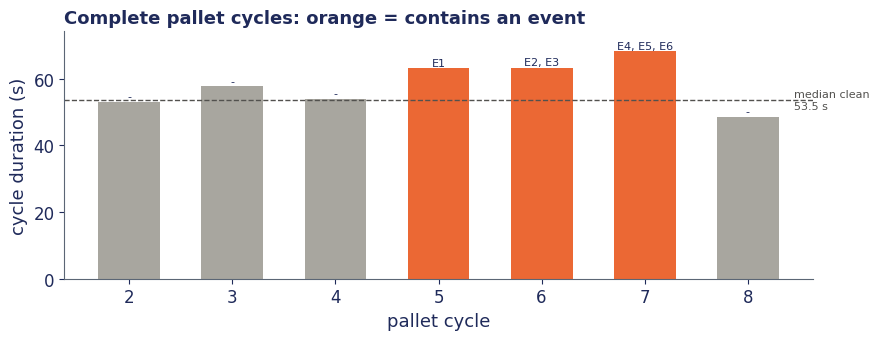

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colours = [C_FLAG if e else C_NORMAL for e in done["events"]]
ax.bar(done["cycle"], done["duration_s"], color=colours, width=0.6)
ax.axhline(baseline, color=INK_2, linestyle="--", linewidth=1)
ax.text(done["cycle"].max() + 0.45, baseline, f"median clean\n"
        f"{baseline:.1f} s", va="center", fontsize=8, color=INK_2)
for _, c in done.iterrows():
    ax.text(c["cycle"], c["duration_s"] + 0.8, c["events"] or "-",
            ha="center", fontsize=8)
ax.set_xticks(done["cycle"])
ax.set_xlabel("pallet cycle")
ax.set_ylabel("cycle duration (s)")
ax.set_ylim(0, done["duration_s"].max() + 6)
ax.set_title("Complete pallet cycles: orange = contains an event",
             loc="left")
fig.tight_layout()
plt.show()

In [16]:
# check: the function cycle_effect gives the same test
v1_done = done
done, eff = cycle_effect(cycles, events)
assert np.isclose(eff["permutation_p"], p_value, atol=1e-4) and np.isclose(eff["clean_median_s"], baseline, atol=1e-3)
print({k: eff[k] for k in ("clean_cycles", "event_cycles", "clean_median_s", "permutation_p", "permutation_splits")})

{'clean_cycles': [2, 3, 4, 8], 'event_cycles': [5, 6, 7], 'clean_median_s': 53.49799999999999, 'permutation_p': 0.02857142857142857, 'permutation_splits': 35}


**Result H7 (measured):**

- Clean cycles take 48.6 to 57.6 s (median 53.5 s). Every cycle with an
  event takes longer (63.1, 63.1, 68.2 s) than every clean cycle.
- p = 0.029 (1 of 35 splits). This is the smallest p-value possible
  with 7 cycles, so the sample is small but the separation is complete.
  **H7 is accepted.**
- The three event cycles took 33.9 s longer than three median clean
  cycles. The lost time of their events adds up to 45.0 s. The
  difference is expected: some equipment waits while other equipment
  keeps working in parallel (for example, in E2 the robot started its
  pick on schedule while the belt was still waiting), so equipment lost
  time is not fully lost for the machine.

## Step 3 - H7 continued: what did the events cost the line?

The v1 analysis compared every cycle with the **median clean cycle** (exact permutation test). But the clean cycles
themselves differ by several seconds, because the pallet cycle is one serial warehouse + robot chain (notebook 03) whose
length depends on **where** the pallet is stored and which lane the returned part came from.

**Position-adjusted normal reference** for cycle i: reference_i = F + H_i + R_i + V_i

* **H_i** horizontal travel predicted from the travel distances with the constant-speed model (notebook 04, extension 4);
* **R_i** robot moves: median duration of the same move type and target lane;
* **V_i** vertical travel as measured (no position model; allowed because no vertical run is flagged or cut by a stop);
* **F** everything else = median over the clean cycles of (observed - H - R - V).

**cycle excess_i = observed_i - reference_i.** This is a *normal* reference - not an ideal (theoretical) cycle time.

In [17]:
handover = chain_handover(done, acts, ctx["moves"])
cref, info = cycle_reference(done, ctx["travel"], ctx["moves"], acts, events, ctx["stops"], ctx["flag_keys"])
v1c = v1_done[["cycle", "extra_vs_baseline_s"]]                 # the v1 table of step 2
cref.merge(v1c, on="cycle")[["cycle", "rack_x", "rack_y", "lane", "events", "observed_s", "reference_s",
                             "cycle_excess_s", "loo_residual_s", "extra_vs_baseline_s"]].round(2)

,cycle,rack_x,rack_y,lane,events,observed_s,reference_s,cycle_excess_s,loo_residual_s,extra_vs_baseline_s
0,2,910,110,blue,,53.06,52.56,0.51,0.77,-0.43
1,3,2330,540,red,,57.64,57.91,-0.27,-0.53,4.14
2,4,1640,540,blue,,53.93,53.67,0.27,0.53,0.43
3,5,910,540,blue,E1,63.06,51.15,11.92,NaN,9.57
4,6,2330,1030,red,E2 E3,63.13,57.21,5.92,NaN,9.63
5,7,1620,1030,red,E4 E5 E6,68.17,52.36,15.81,NaN,14.68
6,8,910,1030,white,,48.55,49.12,-0.57,-0.83,-4.95


In [18]:
print(f"clean cycles: spread of observed times {info['clean_observed_range_s']:.2f} s -> spread of F "
      f"{info['clean_fixed_part_range_s']:.2f} s; leave-one-out error at most {info['clean_loo_max_abs_residual_s']:.2f} s")
print(f"event cycles: {info['event_cycles_excess_s']:.1f} s over reference "
      f"({info['event_cycles_excess_low_s']:.1f}-{info['event_cycles_excess_high_s']:.1f} s), "
      f"while their events sum to {info['event_cycles_equipment_lost_s']:.1f} s of equipment lost time")

clean cycles: spread of observed times 9.09 s -> spread of F 1.07 s; leave-one-out error at most 0.83 s
event cycles: 33.7 s over reference (32.1-35.4 s), while their events sum to 45.0 s of equipment lost time


`extra_vs_baseline_s` is the v1 result (vs. the median clean cycle). The totals are close, but the position-adjusted
reference distributes the excess differently: clean cycles stay within a fraction of a second of their own reference,
so the per-cycle numbers reflect losses rather than rack positions.

**Why the event seconds do not add up:** an overrun lengthens the cycle only if the chain had to wait for it:

In [19]:
display(handover.round(2))
events = events.copy()
events["serial_chain_effect"] = event_chain_effect(events, handover)
events[["event", "cycle", "signals", "equipment_lost_time_s", "serial_chain_effect"]].round(2)

,cycle,events,belt_forward_s,robot_pick_after_belt_start_s,belt_backward_s,warehouse_after_belt_backward_end_s
0,2,,0.85,1.39,0.48,0.00
1,3,,0.85,1.42,0.58,-0.09
2,4,,0.80,1.43,0.60,-0.10
3,5,E1,0.86,1.50,0.65,-0.10
4,6,E2 E3,7.80,1.45,6.79,-0.09
5,7,E4 E5 E6,9.62,7.43,0.56,-0.09
6,8,,0.74,1.38,0.52,-0.10


,event,cycle,signals,equipment_lost_time_s,serial_chain_effect
0,E1,5,WH.Q3_horRack A1.7,10.50,line halted (stop window)
1,E2,6,WH.Q1_beltForward,6.94,ran in parallel with the robot pick (no chain ...
2,E3,6,WH.Q2_beltBackward,6.22,chain delayed: warehouse waited for the belt
3,E4,7,WH.Q1_beltForward,8.77,chain delayed: robot pick 6.0 s later than in ...
4,E5,7,A0.7,2.21,off the warehouse-robot chain (effect not sepa...
5,E6,7,A1.0 WH.Q7_cantForw,10.37,line halted (stop window)
6,E7,9,WH.Q3_horRack,7.19,line halted (stop window)
7,E8,9,WH.Q8_cantBack,4.92,line halted (stop window)


## Step 4 - H8: was any stop missed? (duration-independent check)

The rule only sees outputs that stay ON too long. A halt of the whole line in which every output is OFF would be
invisible to it. So every period in which **no actuator output of either PLC switches** is measured. The longest
such period inside the clean cycles is the normal maximum. Every longer period must lie inside an event or inside a
movement of normal length (v1 step 5.8).

In [20]:
quiet, quiet_limit = quiet_completeness(ctx["data"], ctx["actuators"], ctx["p0"], done, events, acts, ctx["flag_keys"])
print(f"longest quiet period inside clean cycles: {quiet_limit:.2f} s")
quiet.round(2)

longest quiet period inside clean cycles: 3.96 s


,start_s,end_s,duration_s,explained_by
0,255.48,264.26,8.79,inside event E1
1,351.75,357.79,6.04,inside event E4
2,390.14,400.40,10.26,inside event E6
3,453.14,460.68,7.54,inside event E7
4,468.45,473.34,4.89,inside event E8
5,497.87,502.15,4.28,normal move A1.6 (44.95 s <= 54.64 s)


**Result H8 (measured):** 6 periods without any switching are longer
than the 3.96 s seen in clean cycles. 5 lie inside events (E1, E4, E6,
E7, E8). The 6th (4.28 s at 497.9 s) is a horizontal warehouse move of
4.37 s, within its normal range (up to 4.42 s). **H8 is accepted:** no
additional stop is hidden in the data.

## Step 5 - Performance

Performance = sum of reference times / operating time of the complete cycles.

In [21]:
perf = performance_estimates(done, eff, cfg["performance"]["bootstrap_resamples"], cfg["performance"]["bootstrap_seed"], cref)
perf[["method", "reference_basis", "mean_reference_cycle_s", "lost_time_s", "performance"]].round(3)

,method,reference_basis,mean_reference_cycle_s,lost_time_s,performance
0,single reference,fastest clean cycle (upper bound of a single i...,48.551,67.703,0.834
1,single reference,"median clean cycle (typical, not ideal)",53.498,33.074,0.919
2,single reference,bootstrap 2.5% of median clean cycle,48.551,67.703,0.834
3,single reference,bootstrap 97.5% of median clean cycle,57.642,4.066,0.990
4,position-adjusted,"normal reference, median fixed part (primary)",53.424,33.595,0.918
5,position-adjusted,"normal reference, smallest clean fixed part",52.858,37.557,0.908
6,position-adjusted,"normal reference, largest clean fixed part",53.932,30.039,0.926


* **Position-adjusted** (primary): performance relative to demonstrated normal operation. A theoretical cycle time
  can never be slower than a demonstrated one, so this is an **upper bound** of OEE performance.
* **Single reference** (v1 method, kept): depends strongly on which cycle is called "ideal"; the spread comes from
  rack positions, not from losses.
* **Official OEE performance cannot be computed:** the theoretical cycle time is not given (open question A4).

## Step 6 - Evidence register and candidate register

In [22]:
grid = ctx["grid"]                       # time-grid test of notebook 04
register = evidence_register(events, ctx["attr"], flags, feat, quiet, grid)
pd.set_option("display.max_colwidth", 120)
register.T

,0,1,2,3,4,5,6,7
event,E1,E2,E3,E4,E5,E6,E7,E8
start_s,252.422,291.278,314.841,350.796,363.1,385.069,452.992,468.454
end_s,272.172,299.076,321.634,360.419,371.086,400.865,463.282,476.485
equipment_lost_time_s,10.503,6.942,6.223,8.767,2.213,10.366,7.187,4.917
timing_uncertainty_s,0.174,0.19,0.187,0.209,0.152,0.184,0.195,0.186
equipment,Warehouse (WH.Q3_horRack) - abnormal before the protective stop,Warehouse (WH.Q1_beltForward),Warehouse (WH.Q2_beltBackward),Warehouse (WH.Q1_beltForward),Drilling station (A0.7),Drilling station (A1.0) - abnormal before the protective stop,Drilling station (A0.7) - abnormal before the protective stop,"Drilling -> sorting transfer (small conveyor A0.7 / barriers E1.0, E0.1)"
location_confidence,low,high,high,high,high,medium,medium,medium
detection_method,Model 1 step-overrun rule on WH.Q3_horRack A1.7,Model 1 step-overrun rule on WH.Q1_beltForward,Model 1 step-overrun rule on WH.Q2_beltBackward,Model 1 step-overrun rule on WH.Q1_beltForward,Model 1 step-overrun rule on A0.7,Model 1 step-overrun rule on A1.0 WH.Q7_cantForw,Model 1 step-overrun rule on WH.Q3_horRack,Model 1 step-overrun rule on WH.Q8_cantBack
supporting_signals,"WH.Q3_horRack A1.7; stop: A201.0, M0.3, M24.3, VG.safeCurtainShort, E200.0 (reset)",WH.Q1_beltForward,WH.Q2_beltBackward,WH.Q1_beltForward,A0.7,"A1.0 WH.Q7_cantForw; stop: A201.0, M0.3, M24.3, VG.safeCurtainShort, E200.0 (reset)","WH.Q3_horRack; stop: A201.0, M0.3, M24.3, VG.safeCurtainShort, E200.0 (reset)","WH.Q8_cantBack; stop: Visual.start, Visual.Stoplight"
independent_evidence,motor output OFF while request ON; horizontal encoder silent; no actuator switched during the stop window | expected...,expected: pallet reaches the belt light barrier within 0.58 s of belt start; observed: reached after 7.51 s; belt ON...,expected: pallet reaches the belt light barrier within 0.65 s of belt start; observed: reached after 6.70 s; belt ON...,expected: pallet reaches the belt light barrier within 0.58 s of belt start; observed: reached after 9.34 s; belt ON...,expected: part at light barrier E1.0 within 1.00 s; observed: part at E1.0 after 2.56 s,motor output OFF while request ON; no actuator switched during the stop window | expected: drill OFF after its norma...,motor output OFF while request ON; horizontal encoder silent; no actuator switched during the stop window | expected...,motor output OFF while request ON; no actuator switched during the stop window | expected: motor output follows the ...


In [23]:
candidates = candidate_register(flags, ctx["mild"], ctx["mlcmp"], quiet, ctx["min_excess"], UNEXPLAINED,
                                   ctx["km_members"])
candidates.groupby(["source", "status"]).size().rename("candidates")

source                                                   status                               
Line-quiet check (no actuator edge)                      explained                                 6
Model 1 rule (above fence, below detection limit)        abnormal signal behaviour, not a loss     8
Model 1 rule (flagged activation)                        evidence-supported loss                  10
Model 2 Isolation Forest top 20 (A_duration_aware)       anomaly, not a loss                      11
Model 2 Isolation Forest top 20 (B_context_only)         anomaly, not a loss                      15
Model 2 K-Means cluster of long runs (not rule-flagged)  anomaly, not a loss                       2
Name: candidates, dtype: int64

**Alternative explanations that remain possible**

| Events | Accepted reading | Alternative still possible | Why it does not change the decision |
|---|---|---|---|
| curtain stops (E1, E6, E7) | short stop by the safety curtain | a deliberate operator intervention; or booking as availability loss (A6) | lost time and standstill are measured either way |
| belt overruns (E2-E4) | belt or pallet held | belt moving slowly (reduced speed) | both are performance losses; sub-type open |
| small conveyor (E5) | part held at the transfer | slow conveyor; threshold artefact | confirmed by the light barrier, but disappears at stricter thresholds -> lower confidence |
| HMI stop (E8) | operator stop | part removed by hand (barriers change with conveyors OFF) - consistent, not proven | the stop itself is measured |

## Step 9 - The evaluation stage as one function, checked against the steps above

In [24]:
ctx_e = evaluate(ctx)
assert ctx_e["register"]["final_decision"].tolist() == register["final_decision"].tolist()
assert abs(ctx_e["cref_info"]["event_cycles_excess_s"] - info["event_cycles_excess_s"]) < 1e-9
assert len(ctx_e["candidates"]) == len(candidates)
print("the steps above and the evaluation stage agree")

the steps above and the evaluation stage agree


## Step 7 - Quantified results by level

Four quantities are kept strictly apart and never added to each other:

1. **Equipment level** - excess of each flagged step over its own normal duration (notebook 04): *where* a step took
   too long. Stations work in parallel, so these seconds are not production-line loss.
2. **Incident level** - the equipment overruns of one event in chronological order; no additive value.
3. **Cycle level** - observed - position-adjusted reference: the **additional production time**, in s and in % of the
   reference, with the range over the clean-cycle fixed part. E7 and E8 lie in the incomplete cycle 9: only their
   measured standstill (stop-window duration) is reported, not an excess.
4. **Estimated performance** (upper bound) versus **official OEE performance**, which needs the theoretical cycle time
   and is therefore not computable.

In [25]:
cq = cref[["cycle", "events", "observed_s", "reference_s", "reference_low_s", "reference_high_s", "cycle_excess_s"]].copy()
cq["excess_low_s"] = cq["observed_s"] - cq["reference_high_s"]
cq["excess_high_s"] = cq["observed_s"] - cq["reference_low_s"]
cq["excess_pct_of_reference"] = 100 * cq["cycle_excess_s"] / cq["reference_s"]
ev_c = cq[cq["events"].fillna("") != ""]
total = {"cycles": ev_c["cycle"].tolist(), "excess_s": ev_c["cycle_excess_s"].sum(),
         "range_s": (ev_c["excess_low_s"].sum(), ev_c["excess_high_s"].sum()),
         "pct_of_reference": 100 * ev_c["cycle_excess_s"].sum() / ev_c["reference_s"].sum(),
         "pct_range": (100 * ev_c["excess_low_s"].sum() / ev_c["reference_high_s"].sum(),
                       100 * ev_c["excess_high_s"].sum() / ev_c["reference_low_s"].sum())}
display(cq.round(2))
print({k: (np.round(v, 2) if not isinstance(v, list) else v) for k, v in total.items()})

,cycle,events,observed_s,reference_s,reference_low_s,reference_high_s,cycle_excess_s,excess_low_s,excess_high_s,excess_pct_of_reference
0,2,,53.06,52.56,51.99,53.06,0.51,0.00,1.07,0.97
1,3,,57.64,57.91,57.34,58.42,-0.27,-0.77,0.30,-0.46
2,4,,53.93,53.67,53.10,54.17,0.27,-0.24,0.83,0.50
3,5,E1,63.06,51.15,50.58,51.66,11.92,11.41,12.48,23.30
4,6,E2 E3,63.13,57.21,56.64,57.72,5.92,5.41,6.49,10.35
5,7,E4 E5 E6,68.17,52.36,51.79,52.87,15.81,15.31,16.38,30.20
6,8,,48.55,49.12,48.55,49.62,-0.57,-1.07,0.00,-1.15


{'cycles': [5, 6, 7], 'excess_s': np.float64(33.65), 'range_s': array([32.13, 35.35]), 'pct_of_reference': np.float64(20.94), 'pct_range': array([19.8 , 22.23])}


In [26]:
# check against the quantification functions
t = ctx_e["q_total"]
assert t["cycles"] == total["cycles"] and np.isclose(t["excess_s"], total["excess_s"])
assert np.isclose(t["excess_pct"], total["pct_of_reference"])
assert np.allclose([t["excess_low_pct"], t["excess_high_pct"]], total["pct_range"])
assert np.isclose(t["excess_s"], info["event_cycles_excess_s"])            # = the existing cycle-level result
display(ctx_e["q_cycles"][["cycle", "events", "cycle_excess_s", "cycle_excess_pct", "status"]].round(2))
display(ctx_e["q_incidents"][["event", "cycle", "equipment_sequence", "overrun_relation", "stop_window",
                              "measured_standstill_s"]])

,cycle,events,cycle_excess_s,cycle_excess_pct,status
0,2,,0.51,0.97,clean cycle (defines the reference)
1,3,,-0.27,-0.46,clean cycle (defines the reference)
2,4,,0.27,0.50,clean cycle (defines the reference)
3,5,E1,11.92,23.30,complete cycle with events
4,6,E2 E3,5.92,10.35,complete cycle with events
5,7,E4 E5 E6,15.81,30.20,complete cycle with events
6,8,,-0.57,-1.15,clean cycle (defines the reference)
7,9,E7 E8,NaN,NaN,"incomplete cycle (recording ends): no reference, no cycle excess; measured standstill E7 S3 7.60 s; E8 S4 4.90 s"


,event,cycle,equipment_sequence,overrun_relation,stop_window,measured_standstill_s
0,E1,5,WH.Q3_horRack 10.50 s from 255.52 s -> A1.7 8.80 s from 263.37 s,overlapping overruns (2.66 s overlap),S1,8.896
1,E2,6,WH.Q1_beltForward 6.94 s from 292.13 s,single equipment overrun,,NaN
2,E3,6,WH.Q2_beltBackward 6.22 s from 315.41 s,single equipment overrun,,NaN
3,E4,7,WH.Q1_beltForward 8.77 s from 351.65 s,single equipment overrun,,NaN
4,E5,7,A0.7 2.21 s from 368.87 s,single equipment overrun,,NaN
5,E6,7,A1.0 4.08 s from 386.06 s -> WH.Q7_cantForw 10.37 s from 390.50 s,"sequential overruns (0.36 s apart): A1.0 first, then WH.Q7_cantForw",S2,10.377
6,E7,9,WH.Q3_horRack 7.19 s from 456.10 s,single equipment overrun,S3,7.602
7,E8,9,WH.Q8_cantBack 4.92 s from 471.57 s,single equipment overrun,S4,4.904


**Figure functions**

- `_title`: Takeaway title of a figure.
- `_save`: Save a figure at the shared resolution.
- `cycle_effect_figure`: F3: cycle time = normal reference + excess per complete cycle.
- `method_comparison_figure`: F6: rule overruns recovered and extra candidates confirmed, per method.
- `performance_bounds`: F7: performance estimates with their ranges and the 100 % line.

In [27]:
def _title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=15, fontweight="bold")


def _save(fig, path):
    fig.savefig(path, dpi=DPI)
    plt.close(fig)


def cycle_effect_figure(cyc, total, path):
    c = cyc[cyc["reference_s"].notna()].sort_values("cycle")
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    x = c["cycle"].to_numpy()
    base = np.minimum(c["observed_s"], c["reference_s"])
    exc = np.clip(c["cycle_excess_s"], 0, None)
    ax.bar(x, base, color=COLORS["normal"], width=0.62, label="normal reference (position-adjusted)")
    ax.bar(x, exc, bottom=base, color=COLORS["stop"], width=0.62, label="excess over the reference")
    for r in c.itertuples():
        if r.cycle_excess_s < 0:
            ax.hlines(r.reference_s, r.cycle - 0.31, r.cycle + 0.31, color=COLORS["navy"], lw=2)
        txt = f"{r.observed_s:.1f} s"
        if r.events:
            txt = f"{r.events}\n+{r.cycle_excess_s:.1f} s\n" + txt
        ax.text(r.cycle, max(r.observed_s, r.reference_s) + 1, txt, ha="center", va="bottom", fontsize=12,
                fontweight="bold" if r.events else "normal")
    ax.set_xticks(x)
    ax.set_xlabel("pallet cycle (complete cycles); dark line = reference where the cycle was faster")
    ax.set_ylabel("cycle time (s)")
    ax.set_ylim(0, c["observed_s"].max() * 1.42)
    ax.legend(loc="upper left", ncol=2)
    clean = c.loc[c["events"] == "", "cycle_excess_s"].abs().max()
    _title(fig, f"Cycles {', '.join(map(str, total['cycles']))} took {total['excess_s']:.1f} s longer than their "
                f"normal reference ({total['excess_pct']:.1f} %); clean cycles within {clean:.1f} s")
    _save(fig, path)


def method_comparison_figure(ml_q, n_flags, path):
    def val(method, metric):
        m = ml_q[(ml_q["method"] == method) & ml_q["metric"].str.startswith(metric)]
        return int(float(m["value"].iloc[0]))
    rows = [("Rule (Model 1)", n_flags, 0, 0)]
    for lab, m in (("Isolation Forest A", "Isolation Forest A_duration_aware"),
                   ("Isolation Forest B", "Isolation Forest B_context_only")):
        rows.append((lab, val(m, "top-20 items that are rule overruns"), val(m, "additional candidates (top-20"),
                     val(m, "additional candidates longer")))
    rows.append(("K-Means", val("K-Means", "rule overruns in the cluster"), val("K-Means", "additional candidates (cluster"),
                 val("K-Means", "additional candidates longer")))
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    xs = np.arange(len(rows))
    bars = [(-0.27, 1, COLORS["accent"], f"rule-flagged overruns recovered (of {n_flags})"),
            (0.0, 2, COLORS["normal"], "extra candidates checked"),
            (0.27, 3, COLORS["stop"], "extra candidates confirmed as loss")]
    for off, i, col, lab in bars:
        vals = [r[i] for r in rows]
        ax.bar(xs + off, vals, width=0.27, color=col, label=lab)
        for x, v in zip(xs, vals):
            ax.text(x + off, v + 0.3, str(v), ha="center", fontsize=12, fontweight="bold")
    ax.set_xticks(xs)
    ax.set_xticklabels([r[0] for r in rows])
    ax.set_ylim(0, max(r[2] for r in rows) + 4)
    ax.set_ylabel("activations")
    ax.legend(loc="upper left", ncol=3)
    _title(fig, f"Machine learning re-finds up to {max(r[1] for r in rows[1:])} of {n_flags} rule overruns but "
                f"confirms {sum(r[3] for r in rows)} additional losses")
    _save(fig, path)


def performance_bounds(perf, path):
    pos = perf[perf["method"] == "position-adjusted"].set_index("reference_basis")["performance"] * 100
    sing = perf[perf["method"] == "single reference"].set_index("reference_basis")["performance"] * 100
    primary = pos[pos.index.str.contains("primary")].iloc[0]
    median = sing[sing.index.str.startswith("median")].iloc[0]
    fastest = sing[sing.index.str.startswith("fastest")].iloc[0]
    b_lo = sing[sing.index.str.contains("2.5%")].iloc[0]
    b_hi = sing[sing.index.str.contains("97.5%")].iloc[0]
    rows = [("vs position-adjusted normal\nreference (primary)", primary, pos.min(), pos.max(), COLORS["accent"],
             "range over the clean-cycle fixed part"),
            ("single reference:\nmedian clean cycle", median, b_lo, b_hi, COLORS["normal"], "bootstrap of the median"),
            ("single reference:\nfastest clean cycle", fastest, None, None, COLORS["overrun"],
             "upper bound for one ideal time per part")]
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    for y, (lab, v, lo, hi, col, note) in enumerate(rows):
        if lo is not None:
            ax.hlines(y, lo, hi, color=col, lw=7, alpha=0.5)
            note = f"{note}: {lo:.1f}-{hi:.1f} %"
        ax.plot(v, y, "o", color=col, ms=14, zorder=3)
        ax.text(v, y - 0.22, f"{v:.1f} %", ha="center", va="bottom", fontsize=13, fontweight="bold")
        ax.text(80.3, y + 0.3, note, fontsize=12, color=COLORS["muted"], va="center")
    ax.axvline(100, color=COLORS["navy"], lw=1.5, ls="--")
    ax.text(99.8, -0.6, "100 %", fontsize=12, ha="right")
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows])
    ax.set_ylim(len(rows) - 0.4, -0.8)
    ax.set_xlim(80, 101)
    ax.set_xlabel("performance (% of the operating time explained by the reference)")
    _title(fig, f"Performance {primary:.1f} % of demonstrated normal operation (upper bound);\n"
                "official OEE performance needs the ideal cycle time, which is not given")
    _save(fig, path)

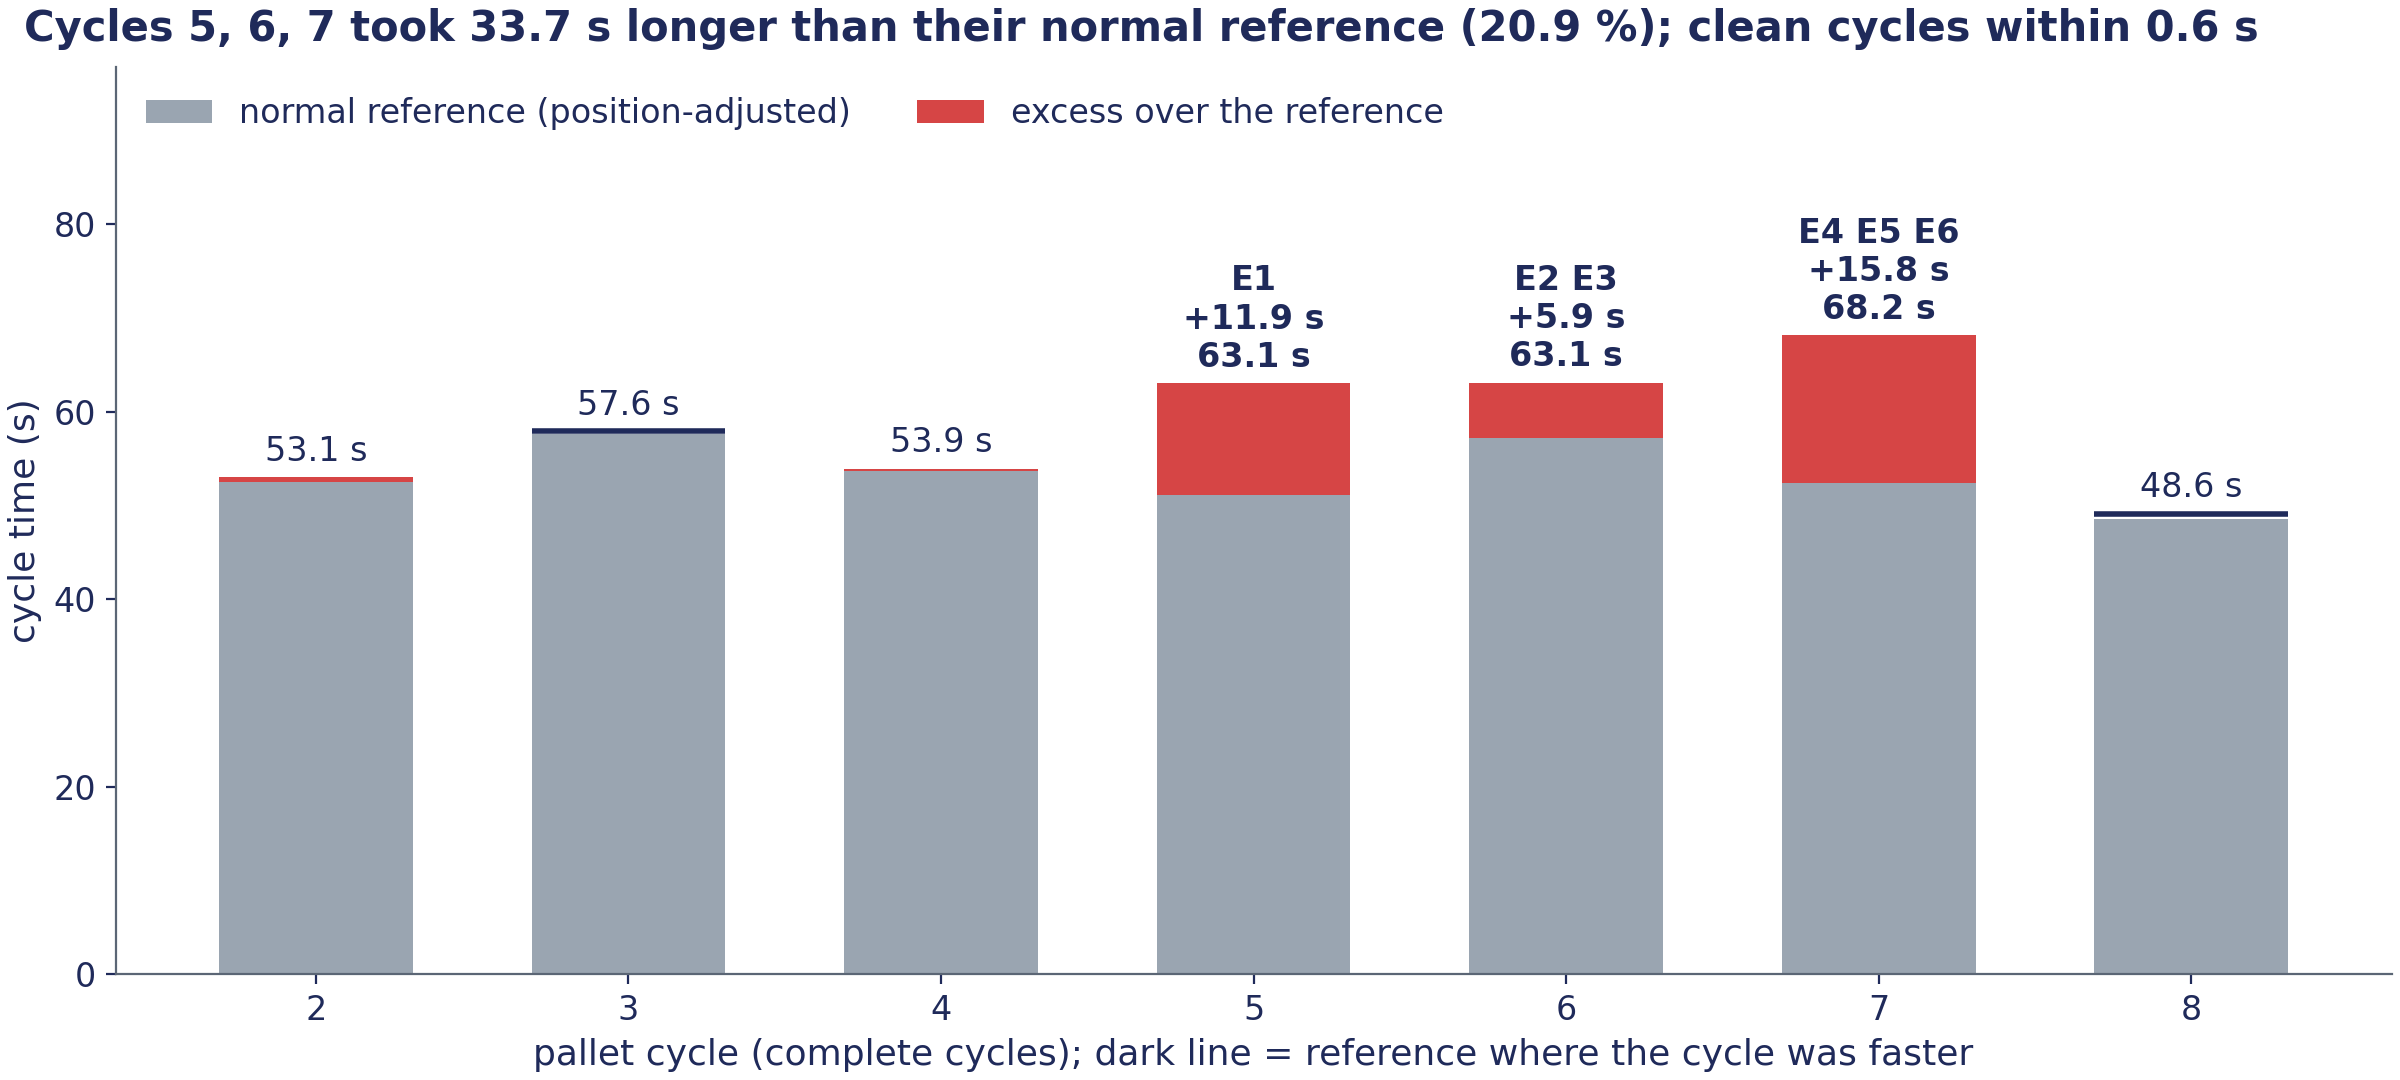

In [28]:
cycle_effect_figure(ctx_e["q_cycles"], ctx_e["q_total"], FIGURES / "cycle_effect.png")
display(Image(filename=str(FIGURES / "cycle_effect.png"), width=900))

### Results by level, and all methods compared

In [29]:
pd.set_option("display.max_colwidth", 140)
display(ctx_e["q_levels"][["level", "value", "limitation"]])
ctx_e["q_methods"]

,level,value,limitation
0,1 equipment,2.21-10.50 s per overrun (10 overruns); excess relative to median normal duration 38-1092 %,"diagnoses where a step took too long; stations work in parallel, so these seconds are not additive and are not production-line loss"
1,2 incident,"8 incidents; E1: overlapping overruns (2.66 s overlap); E6: sequential overruns (0.36 s apart): A1.0 first, then WH.Q7_cantForw",no additive incident value is assigned
2,3 cycle,"33.65 s (32.13-35.35 s) = 20.9 % (19.8-22.2 %) of the reference of cycles 5, 6, 7",complete cycles only; the reference rests on 4 clean cycles
3,3 cycle (incomplete),E7 S3 7.60 s; E8 S4 4.90 s,"measured standstill duration, not automatically excess production time (no reference for an incomplete cycle)"
4,4 estimated performance,91.8 % (90.8-92.6 %),relative to demonstrated normal operation: an upper bound of OEE performance
5,5 official OEE performance,not available: theoretical (ideal) cycle time not given (A4); with one ideal time per part it is at most 83.4 %,needs the design cycle time
6,Model 2,0; anomaly scores give no seconds or percentages,"anomalies are candidates, not confirmed losses"


,method,purpose,finding,quantified_loss,limitation
0,Model 1 - engineering rule + PLC evidence,find steps far longer than normal and confirm them with independent signals,10 equipment overruns in 8 incidents,2.21-10.50 s per overrun (10 overruns); excess relative to median normal duration 38-1092 %,equipment level only; stop vs slow not separable for belt and small conveyor
1,"Model 2 - Isolation Forest (sets A, B)",look for abnormal activations the rule misses,"additional candidates in the top 20: A 11, B 18; longer than normal and unexplained: 0","none: anomaly scores are rankings, not seconds",anomaly count set by contamination; agreement with the rule is not validation
2,Model 2 - K-Means,test for natural groups of activations,cluster of long runs: 7 rule overruns + 2 other runs; unexplained: 0,none,weak overall structure (low silhouette)
3,Line-quiet check (H8),find whole-line halts the duration rule cannot see,"6 long quiet periods, 0 unexplained",none beyond the events,limit taken from the 4 clean cycles
4,Cycle-level evaluation (H7),measure the additional production time,"cycles 5, 6, 7 longer than their position-adjusted reference; permutation p = 0.029","33.65 s (32.13-35.35 s) = 20.9 % (19.8-22.2 %) of the reference of cycles 5, 6, 7","complete cycles only; E7, E8 lie in the incomplete cycle"
5,Performance estimate,express the cycle-level loss as performance,performance relative to demonstrated normal operation,91.8 % (90.8-92.6 %),upper bound; official OEE performance not computable (no ideal cycle time)


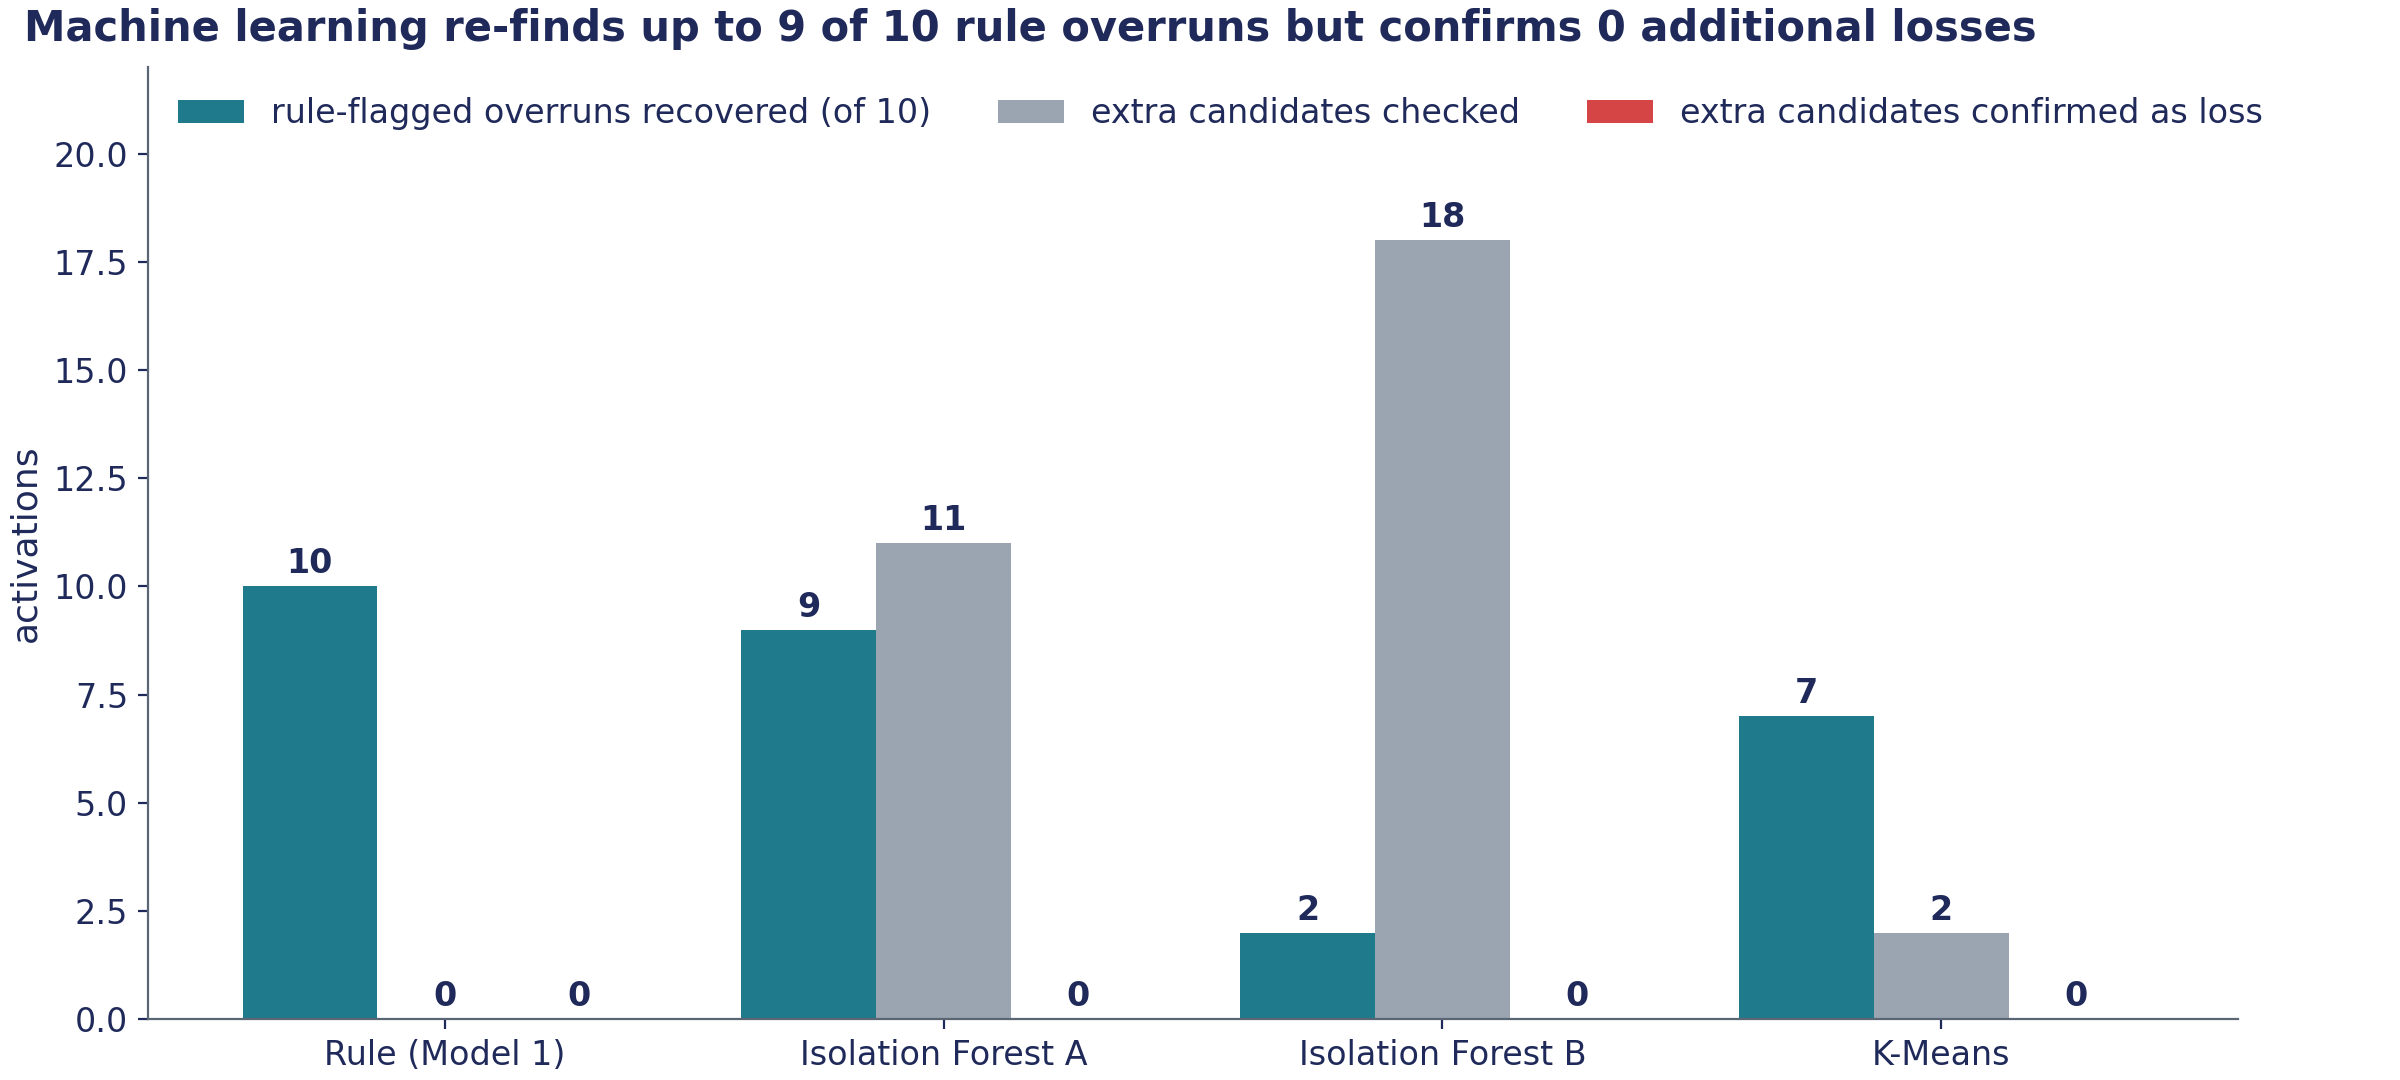

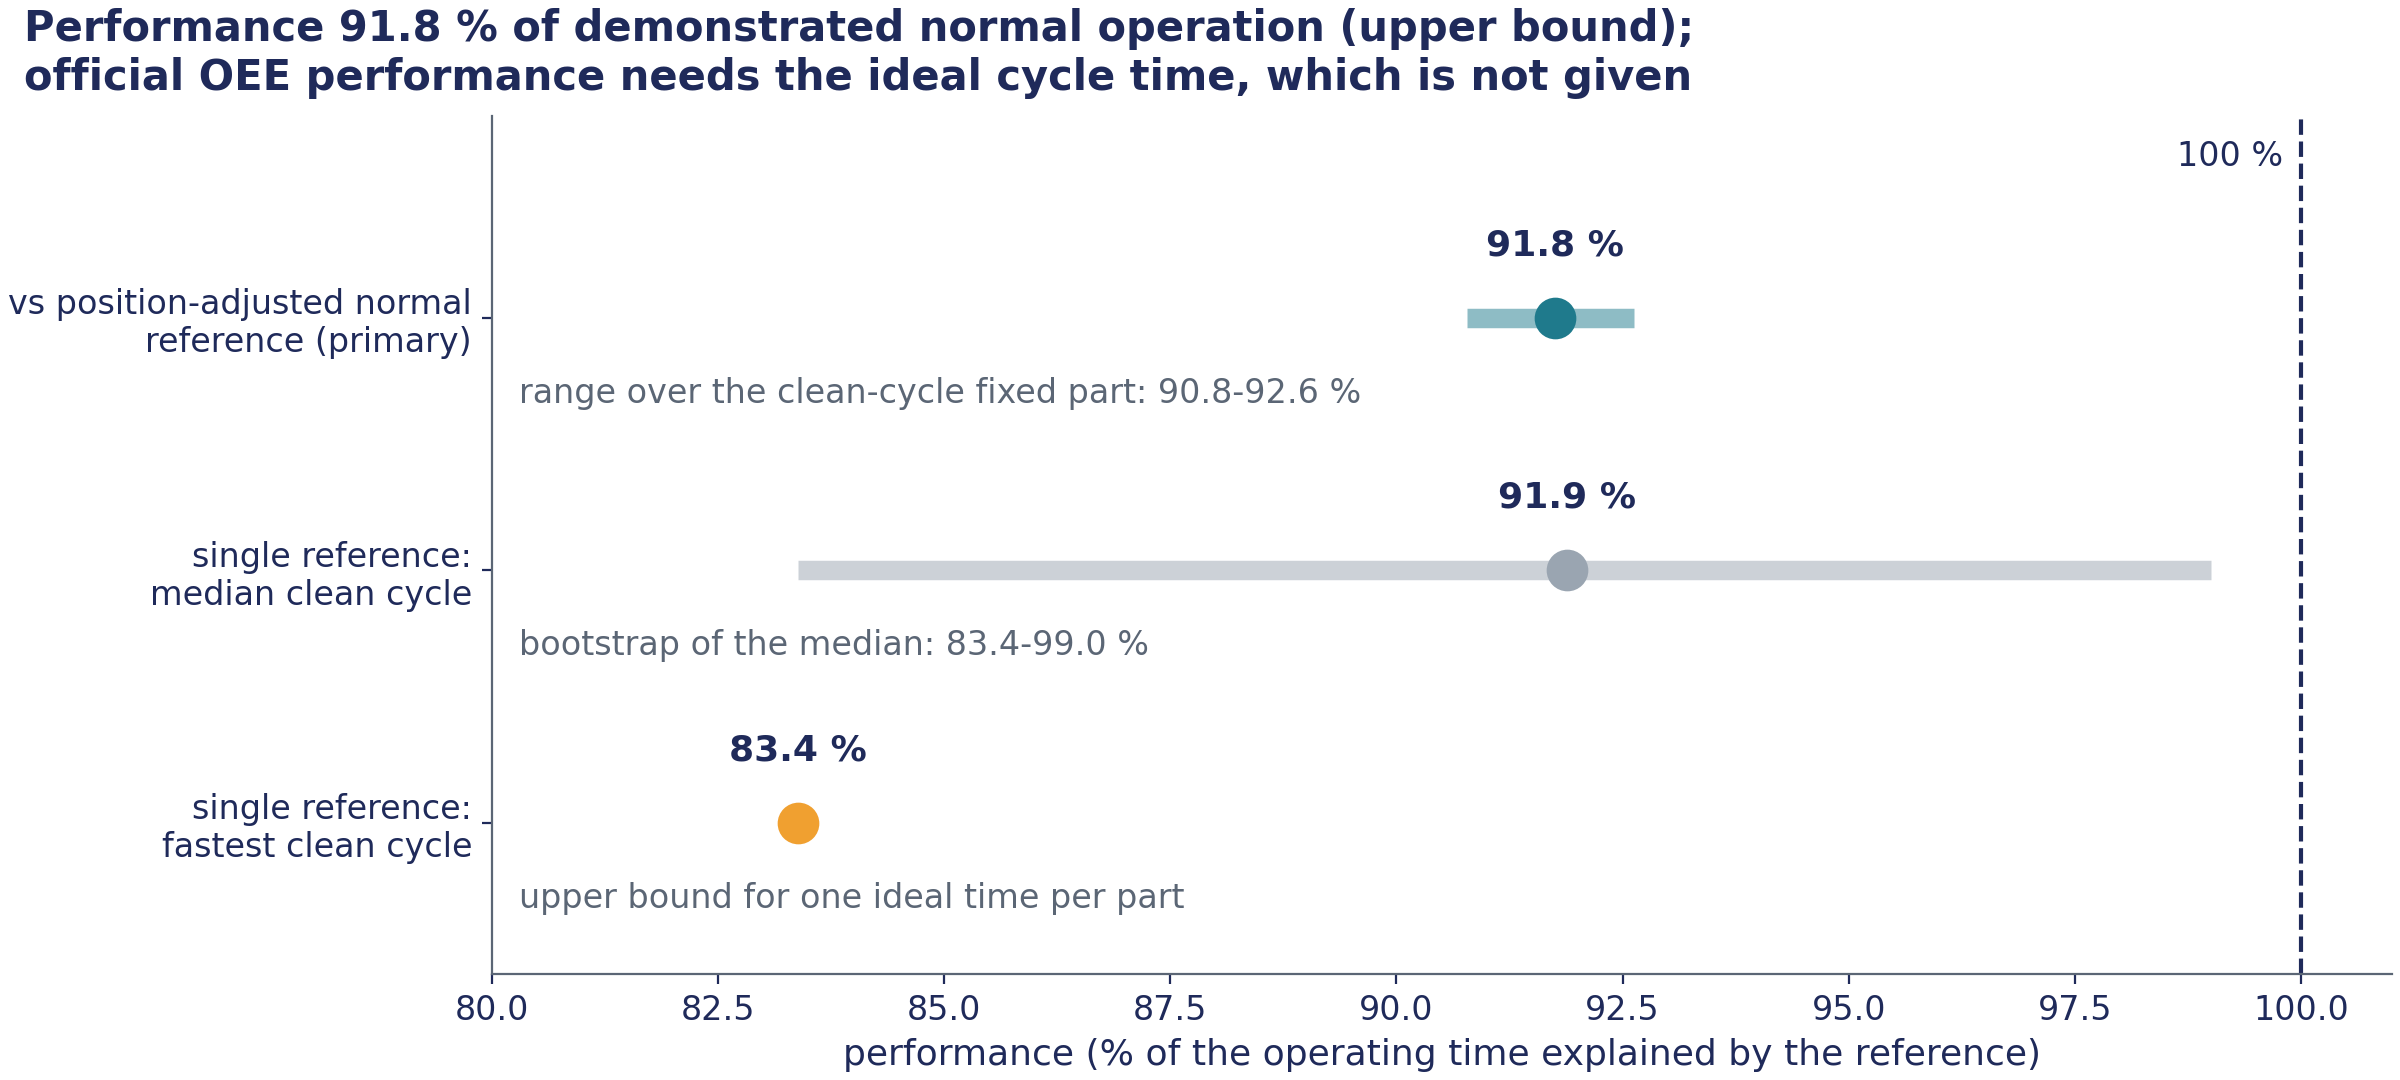

In [30]:
method_comparison_figure(ctx_e["q_ml"], len(ctx_e["flags"]), FIGURES / "method_comparison.png")
performance_bounds(ctx_e["perf"], FIGURES / "performance_bounds.png")
for name in ("method_comparison", "performance_bounds"):
    display(Image(filename=str(FIGURES / f"{name}.png"), width=900))

## Final results

**Found: 8 performance-loss events** in the production window (8.9 to 505.8 s), each with start, end, lost time,
equipment and independent PLC evidence (v1 summary, confirmed by the evaluation above):

- E1 (252 s; horizontal axis 10.5 s, vacuum suction 8.8 s, overlapping): safety curtain stop. Warehouse horizontal
  axis and drilling-station vacuum suction wait. The axis was already waiting 3.0 s before the curtain signal.
- E2 (291 s, 6.9 s): warehouse belt forward, pallet 7.5 s late at the outside barrier. No cause signal.
- E3 (315 s, 6.2 s): warehouse belt backward, pallet 6.7 s late at the inside barrier. No cause signal.
- E4 (351 s, 8.8 s): warehouse belt forward, pallet 9.3 s late. No cause signal.
- E5 (363 s, 2.2 s): drilling-station small conveyor, part 1.6 s late at its barrier. No cause signal. Weakest
  detection (threshold-sensitive).
- E6 (385 s; drill 4.1 s, then cantilever 10.4 s - two sequential equipment overruns, not added): drill ON 4 s too
  long, then safety curtain stop. Warehouse cantilever waits.
- E7 (453 s, 7.2 s): safety curtain stop. Warehouse horizontal axis waits.
- E8 (468 s, 4.9 s): HMI stop. Warehouse cantilever waits (threshold-sensitive).

| # | Hypothesis | Outcome | Notebook |
|---|---|---|---|
| H1 | clocks agree | supported within the tested span; results insensitive to a 1 s shift | 03 |
| H2 | one repeated pallet cycle | accepted | 03 |
| H3 | losses = activations far longer than normal | accepted: 10 activations, 8 events | 04 |
| H4 | detections are real | accepted | 04 |
| H5 | extra time is a standstill | proven for 4 of 8; not separable for the belt / conveyor events | 04 |
| H6 | cause visible | 4 of 8 (3 curtain stops, 1 HMI stop) | 04 |
| H7 | events lengthen the cycle | supported: p = 0.029; event cycles 33.7 s over their position-adjusted reference; equipment seconds are not additive | 06 |
| H8 | no stop missed | supported: every long quiet period is explained | 06 |
| H9 | reduced speed exists | not supported | 04 |
| H10 | ML finds losses the rule misses | not supported: Model 2 adds no verifiable loss | 05 |

| Quantity | Value | Meaning |
|---|---|---|
| Equipment-level excess | 2.2-10.5 s per overrun (10 overruns), 38-1092 % of the median normal duration | where steps took too long; not additive, not line loss |
| Additional production-cycle time | 33.65 s (32.13-35.35 s) = 20.9 % (19.8-22.2 %) of the reference of cycles 5-7 | the production impact of E1-E6 |
| Measured standstill, incomplete cycle 9 | E7 7.60 s (S3), E8 4.90 s (S4) | not automatically excess production time |
| Estimated performance | 91.8 % (90.8-92.6 %) vs. demonstrated normal operation | upper bound of OEE performance |
| Official OEE performance | not computable (no theoretical cycle time, A4); with one ideal time per part at most 83.4 % | needs the design cycle time |
| Model 2 | 0 independently verified additional losses; no seconds from anomaly scores | anomalies are candidates only |

**Limitations:** one recording (4 clean cycles for the fixed part F), no labels, no motion sensor on belt and small
conveyor, causes of curtain stops not recorded, the last cycle is incomplete (only standstill measurable for E7, E8),
clock agreement tested only during the curtain stops, no theoretical cycle time (official OEE performance cannot be
computed - open question A4), whether curtain stops count as performance or availability losses (A6).

## The evidence workbook

Every evidence table of notebooks 02-06 as one sheet of `reports/evidence_tables.xlsx`, with an index sheet.

**Evidence workbook**

- `TABLE_GROUPS`: Sheets of the evidence workbook, grouped by notebook.

In [31]:
# Evidence tables (sheets of reports/evidence_tables.xlsx), grouped by the notebook that explains them.
TABLE_GROUPS = {
    "02_data_understanding": ["signal_dictionary", "sampling", "gaps", "sync_check", "shortest_pulses"],
    "03_data_preparation": ["resample_loss", "resample_event_sensitivity", "stops", "stop_halt_check", "cycles",
                            "drilling_cycles", "robot_moves"],
    "04_model_1": ["normal_durations", "events_rule", "threshold_sweep", "slow_steps", "step_dispersion",
                   "warehouse_travel", "attribution", "paired_output_windows", "encoder_silence", "belt_arrivals",
                   "barrier_changes_belt_off", "small_conveyor_arrivals", "barrier_edges_without_drive",
                   "equipment_quantification"],
    "05_model_2": ["ml_isolation_forest", "ml_contamination_sweep", "ml_kmeans", "ml_vs_rule", "ml_quantification"],
    "06_evaluation": ["line_quiet_periods", "cycle_reference", "cycle_handover", "performance", "events_final",
                      "event_evidence_register", "candidate_register", "incident_quantification",
                      "cycle_quantification", "results_by_level", "method_comparison"],
}

- `TABLES`: Sheet name -> result of the analysis.
- `evidence_tables`: All evidence tables as DataFrames, rounded and typed exactly as they are stored.
- `write_evidence_workbook`: One sheet per evidence table, in notebook order, plus an index sheet.

In [32]:
TABLES = {  # table name -> ctx key (one sheet each in reports/evidence_tables.xlsx)
    "signal_dictionary": "dictionary", "sampling": "sampling", "gaps": "gaps", "sync_check": "sync",
    "shortest_pulses": "pulses", "resample_loss": "resample", "resample_event_sensitivity": "grid",
    "stops": "stops", "stop_halt_check": "halt", "cycles": "done", "drilling_cycles": "dcyc", "robot_moves": "moves",
    "normal_durations": "stats", "events_rule": "flags", "threshold_sweep": "sweep", "slow_steps": "mild",
    "step_dispersion": "disp", "warehouse_travel": "travel", "attribution": "attr",
    "paired_output_windows": "drive_off_all", "encoder_silence": "enc", "belt_arrivals": "belt",
    "barrier_changes_belt_off": "belt_off_bar", "small_conveyor_arrivals": "conv",
    "barrier_edges_without_drive": "no_drive", "ml_isolation_forest": "if_res", "ml_contamination_sweep": "if_sweep",
    "ml_kmeans": "km", "ml_vs_rule": "mlcmp", "line_quiet_periods": "quiet", "cycle_reference": "cref",
    "cycle_handover": "handover", "performance": "perf", "events_final": "events",
    "event_evidence_register": "register", "candidate_register": "candidates",
    "equipment_quantification": "q_equipment", "incident_quantification": "q_incidents",
    "cycle_quantification": "q_cycles", "ml_quantification": "q_ml", "results_by_level": "q_levels",
    "method_comparison": "q_methods",
}


def evidence_tables(ctx: dict) -> dict:
    """All evidence tables as DataFrames, rounded and typed exactly as they are stored."""
    T = {}
    for name, key in TABLES.items():
        df = ctx[key].reset_index() if name == "normal_durations" else ctx[key]
        T[name] = pd.read_csv(StringIO(df.round(4).to_csv(index=False)))
    return T


def write_evidence_workbook(T: dict, path) -> None:
    """One sheet per evidence table, in notebook order, plus an index sheet."""
    order = [(g, n) for g, names in TABLE_GROUPS.items() for n in names]
    index = pd.DataFrame([{"sheet": n, "notebook": g, "rows": len(T[n]), "columns": T[n].shape[1]} for g, n in order])
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        index.to_excel(xw, sheet_name="index", index=False)
        for _, n in order:
            T[n].to_excel(xw, sheet_name=n, index=False)

In [33]:
T = evidence_tables(ctx_e)
write_evidence_workbook(T, cfg["paths"]["reports_dir"] / "evidence_tables.xlsx")
print(len(T), "sheets + index ->", cfg["paths"]["reports_dir"] / "evidence_tables.xlsx")

42 sheets + index -> C:\Users\Harsha Vardhan\Downloads\optimizing_performance_loss\applied-industrial-ai-manufacturing\reports\evidence_tables.xlsx


### How to reproduce

```
pip install -r requirements.txt
# run notebooks/01 ... 06 in order (each hands its results to the next through data/processed/)
python run_mp1.py          # optional: the same figures and evidence workbook without Jupyter
```